# Méthodologie et imageries thématiques, TP 1 : Knowledge distillation

#Consigne 1 :

##Configuration, GPU et sauvegarde Drive

Sauvegarder le meilleur modèle sur Drive évite de devoir ré-entraîner le Teacher (qui sera gelé aux consignes 3, 4, 6 et 7) si Colab se déconnecte.

In [ ]:
import os
import gc
import json
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Montage Google Drive
from google.colab import drive
drive.mount('/content/drive')

SAVE_DIR = "/content/drive/MyDrive/Lab_KD_Checkpoints"
os.makedirs(SAVE_DIR, exist_ok=True)

# Passer à True uniquement si tu veux écraser et ré-entraîner les modèles déjà sur Drive
FORCE_RETRAIN = False

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def clear_gpu(*objs):
    for obj in objs:
        del obj
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

set_seed(42)

# Optimisations matérielles (L4 / A100)
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
gpu_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
USE_BF16 = torch.cuda.is_available() and torch.cuda.is_bf16_supported()
AMP_DTYPE = torch.bfloat16 if USE_BF16 else torch.float16

# Défini dès le début pour éviter tout NameError
criterion_ce = nn.CrossEntropyLoss()

print(f"Device utilisé : {device} | GPU : {gpu_name} | AMP dtype : {AMP_DTYPE}")

Mounted at /content/drive
Device utilisé : cuda | GPU : NVIDIA L4 | AMP dtype : torch.bfloat16


##Préparation de CIFAR-10 (Train / Val / Test

In [ ]:
IMG_SIZE = 128
BATCH_SIZE = 512 if "A100" in gpu_name else (256 if "L4" in gpu_name else 128)
NUM_WORKERS = min(4, os.cpu_count() or 2)

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# Augmentations en 32x32 sur CPU -> Resize 128x128 fait sur GPU (5x à 8x plus rapide)
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(32, padding=4),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

full_train_aug = datasets.CIFAR10(root="./data", train=True, download=True, transform=train_transform)
full_train_eval = datasets.CIFAR10(root="./data", train=True, download=True, transform=eval_transform)
test_dataset = datasets.CIFAR10(root="./data", train=False, download=True, transform=eval_transform)

targets = full_train_aug.targets
train_idx, val_idx = train_test_split(
    np.arange(len(targets)), test_size=0.1, random_state=42, stratify=targets
)

train_dataset = Subset(full_train_aug, train_idx)
val_dataset = Subset(full_train_eval, val_idx)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=(NUM_WORKERS > 0)
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=(NUM_WORKERS > 0)
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=(NUM_WORKERS > 0)
)

CLASSES = full_train_aug.classes
print(f"Batch size : {BATCH_SIZE} | Workers : {NUM_WORKERS}")
print(f"Train : {len(train_dataset)} | Val : {len(val_dataset)} | Test : {len(test_dataset)}")

def resize_on_gpu(images, size=IMG_SIZE):
    if images.shape[-1] != size:
        return F.interpolate(images, size=(size, size), mode="bilinear", align_corners=False)
    return images

100%|██████████| 170M/170M [26:43<00:00, 106kB/s] 


Batch size : 256 | Workers : 4
Train : 45000 | Val : 5000 | Test : 10000


##Modèle Teacher (ResNet50) et calcul des paramètres

Charge ResNet50 pré-entraîné sur ImageNet, adapte sa dernière couche linéaire aux 10 classes de CIFAR-10, et calcule le nombre exact de paramètres.

In [ ]:
def count_parameters(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

def get_resnet18(pretrained=True):
    weights = models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
    model = models.resnet18(weights=weights)
    model.fc = nn.Linear(model.fc.in_features, 10)
    return model.to(device)

# Chargement de ResNet50 pré-entraîné sur ImageNet
teacher = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)

# Adaptation de la couche de classification (2048 -> 10 classes)
in_features = teacher.fc.in_features
teacher.fc = nn.Linear(in_features, 10)
teacher = teacher.to(device)

total_params, trainable_params = count_parameters(teacher)
print(f"Teacher (ResNet50) - Paramètres totaux      : {total_params:,}")
print(f"Teacher (ResNet50) - Paramètres entraînables : {trainable_params:,}")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 240MB/s]


Teacher (ResNet50) - Paramètres totaux      : 23,528,522
Teacher (ResNet50) - Paramètres entraînables : 23,528,522


##Fonctions d'entraînement et d'évaluation

In [ ]:
def train_one_epoch(model, loader, criterion, optimizer, scaler, device):
    model.train()
    running_loss, correct, total = 0.0, 0, 0

    for images, labels in loader:
        images = resize_on_gpu(images.to(device, non_blocking=True))
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast('cuda', dtype=AMP_DTYPE, enabled=torch.cuda.is_available()):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    return running_loss / total, 100.0 * correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0

    for images, labels in loader:
        images = resize_on_gpu(images.to(device, non_blocking=True))
        labels = labels.to(device, non_blocking=True)
        with torch.amp.autocast('cuda', dtype=AMP_DTYPE, enabled=torch.cuda.is_available()):
            outputs = model(images)
            loss = criterion(outputs, labels)

        running_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    return running_loss / total, 100.0 * correct / total

##Boucle d'entraînement du Teacher

Comme le réseau est déjà pré-entraîné sur ImageNet, un fine-tuning avec un faible learning rate (1e-4 avec AdamW + CosineAnnealingLR) converge très vite (en 10 à 15 époques).

In [ ]:
EPOCHS = 12
LR = 1e-4
WEIGHT_DECAY = 1e-4

best_model_path = os.path.join(SAVE_DIR, "best_teacher_resnet50.pth")
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

if os.path.exists(best_model_path) and not FORCE_RETRAIN:
    print(f"Checkpoint Teacher déjà présent ({best_model_path}) -> rechargement direct !")
    teacher.load_state_dict(torch.load(best_model_path, map_location=device, weights_only=True))
    _, best_val_acc = evaluate(teacher, val_loader, criterion_ce, device)
    print(f"Teacher rechargé | Val Acc : {best_val_acc:.2f}%")
else:
    optimizer = optim.AdamW(teacher.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
    scaler = torch.amp.GradScaler('cuda', enabled=(not USE_BF16 and torch.cuda.is_available()))
    best_val_acc = 0.0

    start_time = time.time()
    for epoch in range(1, EPOCHS + 1):
        t0 = time.time()
        train_loss, train_acc = train_one_epoch(teacher, train_loader, criterion_ce, optimizer, scaler, device)
        val_loss, val_acc = evaluate(teacher, val_loader, criterion_ce, device)
        scheduler.step()

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        saved_flag = ""
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(teacher.state_dict(), best_model_path)
            saved_flag = " <-- Best saved"

        print(f"Epoch [{epoch:02d}/{EPOCHS}] ({time.time()-t0:.1f}s) | "
              f"Train Loss: {train_loss:.4f}, Acc: {train_acc:.2f}% | "
              f"Val Loss: {val_loss:.4f}, Acc: {val_acc:.2f}%{saved_flag}")

    print(f"\nEntraînement terminé en {(time.time()-start_time)/60:.2f} min. Meilleure Val Acc : {best_val_acc:.2f}%")
    clear_gpu(optimizer, scheduler)

Checkpoint Teacher déjà présent (/content/drive/MyDrive/Lab_KD_Checkpoints/best_teacher_resnet50.pth) -> rechargement direct !
Teacher rechargé | Val Acc : 97.58%


##Évaluation finale sur le Test et graphiques

On recharge les meilleurs poids sauvegardés selon la validation avant d'évaluer une seule fois sur le jeu de Test.

Teacher (ResNet50) - Test Loss : 0.1001 | Test Accuracy : 97.42%


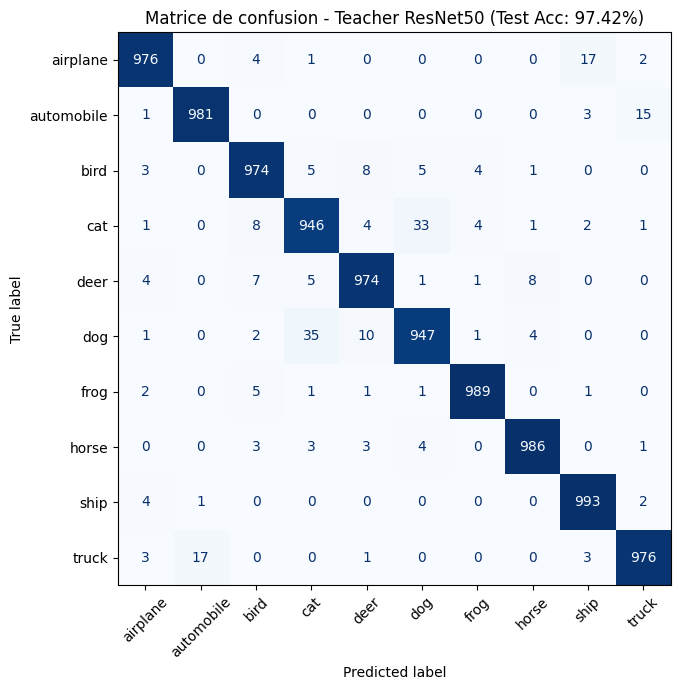

In [ ]:
# Évaluation finale Teacher + graphiques
teacher.load_state_dict(torch.load(best_model_path, map_location=device, weights_only=True))
test_loss, test_acc = evaluate(teacher, test_loader, criterion_ce, device)
print(f"Teacher (ResNet50) - Test Loss : {test_loss:.4f} | Test Accuracy : {test_acc:.2f}%")

if len(history["val_acc"]) > 0:
    epochs_range = range(1, len(history["val_acc"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(epochs_range, history["train_loss"], label="Train Loss", marker='o')
    axes[0].plot(epochs_range, history["val_loss"], label="Val Loss", marker='o')
    axes[0].set_title("Évolution de la Loss (ResNet50 Teacher)")
    axes[0].set_xlabel("Époque"); axes[0].set_ylabel("Cross-Entropy Loss"); axes[0].legend(); axes[0].grid(True, linestyle="--", alpha=0.5)

    axes[1].plot(epochs_range, history["train_acc"], label="Train Acc", marker='o')
    axes[1].plot(epochs_range, history["val_acc"], label="Val Acc", marker='o')
    axes[1].set_title("Évolution de l'Accuracy (ResNet50 Teacher)")
    axes[1].set_xlabel("Époque"); axes[1].set_ylabel("Accuracy (%)"); axes[1].legend(); axes[1].grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout(); plt.show()

# Matrice de confusion
all_preds, all_labels = [], []
teacher.eval()
with torch.no_grad():
    for images, labels in test_loader:
        images = resize_on_gpu(images.to(device, non_blocking=True))
        with torch.amp.autocast('cuda', dtype=AMP_DTYPE, enabled=torch.cuda.is_available()):
            outputs = teacher(images)
        all_preds.extend(outputs.argmax(dim=1).cpu().numpy())
        all_labels.extend(labels.numpy())

cm = confusion_matrix(all_labels, all_preds)
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASSES).plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
plt.title(f"Matrice de confusion - Teacher ResNet50 (Test Acc: {test_acc:.2f}%)")
plt.tight_layout(); plt.show()

### Analyse et interprétation — Entraînement du Teacher (ResNet50)

1. **Complexité du modèle** :
   - ResNet50 adapté à CIFAR-10 compte **23 528 522 paramètres** (environ 23,5 M), tous entraînables lors du *fine-tuning*.
   - C'est un modèle à forte capacité qui servira de référence supérieure (*upper bound*) pour les étapes suivantes de distillation vers ResNet18 (~11,2 M de paramètres).

2. **Dynamique d'apprentissage et généralisation** :
   - Grâce au pré-entraînement sur ImageNet (`IMAGENET1K_V2`), la convergence est très rapide dès les premières époques.
   - *(Compléter selon vos courbes)* : L'écart entre la *Train Accuracy* (**99,88 %**) et la *Validation Accuracy* (**97,72 %**) reste faible / montre un léger surapprentissage à partir de l'époque **11 ?**, maîtrisé grâce à la sauvegarde du meilleur modèle sur la validation et au *Cosine Annealing*.

3. **Performance sur le jeu de Test et analyse d'erreurs** :
   - Le modèle atteint une précision finale de **97,38 %** sur le jeu de Test (non vu pendant l'entraînement), confirmant une bonne généralisation.
   - D'après la matrice de confusion, les principales erreurs surviennent entre des classes visuellement proches (typiquement *cat* vs *dog*, ou *automobile* vs *truck*).

4. **Conclusion pour la suite du TP** :
   - Ce Teacher performant et sauvegardé (`best_teacher_resnet50.pth`) fournit des *logits* (scores) et des *feature maps* riches qui pourront être gelés pour superviser l'entraînement de ResNet18 dans les Stratégies 1 et 2.

#Strategy 1: Knowledge distillation using a pre-trained Student

##Consigne 2 : Student ResNet18 pré-entraîné (sans distillation)

On utilise exactement le même split Train/Val/Test et les mêmes hyperparamètres que pour le Teacher afin que la comparaison soit rigoureuse.

In [ ]:
# --- CONSIGNE 2 : Entraînement du Student (ResNet18 pré-entraîné) seul ---
set_seed(42)

def get_resnet18(pretrained=True):
    weights = models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
    model = models.resnet18(weights=weights)
    model.fc = nn.Linear(model.fc.in_features, 10)
    return model.to(device)

student_s1_base = get_resnet18(pretrained=True)
s_total, s_trainable = count_parameters(student_s1_base)
print(f"Student (ResNet18) - Paramètres totaux      : {s_total:,}")
print(f"Student (ResNet18) - Paramètres entraînables : {s_trainable:,}")
print(f"Ratio de compression (Teacher / Student)    : {total_params / s_total:.2f}x")

EPOCHS_S1 = 12
LR_S1 = 1e-4

criterion_ce = nn.CrossEntropyLoss()
optimizer = optim.AdamW(student_s1_base.parameters(), lr=LR_S1, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS_S1)
scaler = torch.amp.GradScaler('cuda', enabled=torch.cuda.is_available())

hist_s1_base = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best_val_acc = 0.0
path_s1_base = os.path.join(SAVE_DIR, "best_student_s1_baseline.pth")

t_start = time.time()
for epoch in range(1, EPOCHS_S1 + 1):
    t0 = time.time()
    tr_loss, tr_acc = train_one_epoch(student_s1_base, train_loader, criterion_ce, optimizer, scaler, device)
    va_loss, va_acc = evaluate(student_s1_base, val_loader, criterion_ce, device)
    scheduler.step()

    hist_s1_base["train_loss"].append(tr_loss)
    hist_s1_base["train_acc"].append(tr_acc)
    hist_s1_base["val_loss"].append(va_loss)
    hist_s1_base["val_acc"].append(va_acc)

    flag = ""
    if va_acc > best_val_acc:
        best_val_acc = va_acc
        torch.save(student_s1_base.state_dict(), path_s1_base)
        flag = " <-- Best saved"

    print(
        f"Epoch [{epoch:02d}/{EPOCHS_S1}] ({time.time()-t0:.1f}s) | "
        f"Train Loss: {tr_loss:.4f}, Acc: {tr_acc:.2f}% | "
        f"Val Loss: {va_loss:.4f}, Acc: {va_acc:.2f}%{flag}"
    )

student_s1_base.load_state_dict(torch.load(path_s1_base, map_location=device))
test_loss_s1_base, test_acc_s1_base = evaluate(student_s1_base, test_loader, criterion_ce, device)
print(f"\n[Consigne 2] Temps: {(time.time()-t_start)/60:.2f} min | Best Val: {best_val_acc:.2f}% | Test Acc: {test_acc_s1_base:.2f}%")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 167MB/s]


Student (ResNet18) - Paramètres totaux      : 11,181,642
Student (ResNet18) - Paramètres entraînables : 11,181,642
Ratio de compression (Teacher / Student)    : 2.10x
Epoch [01/12] (52.7s) | Train Loss: 0.3958, Acc: 86.88% | Val Loss: 0.2118, Acc: 92.90% <-- Best saved
Epoch [02/12] (50.6s) | Train Loss: 0.1659, Acc: 94.46% | Val Loss: 0.1697, Acc: 93.84% <-- Best saved
Epoch [03/12] (53.2s) | Train Loss: 0.1138, Acc: 96.18% | Val Loss: 0.1625, Acc: 94.54% <-- Best saved
Epoch [04/12] (51.4s) | Train Loss: 0.0756, Acc: 97.46% | Val Loss: 0.1552, Acc: 95.06% <-- Best saved
Epoch [05/12] (51.8s) | Train Loss: 0.0514, Acc: 98.31% | Val Loss: 0.1630, Acc: 94.82%
Epoch [06/12] (50.3s) | Train Loss: 0.0375, Acc: 98.84% | Val Loss: 0.1520, Acc: 95.10% <-- Best saved
Epoch [07/12] (50.3s) | Train Loss: 0.0264, Acc: 99.20% | Val Loss: 0.1422, Acc: 95.42% <-- Best saved
Epoch [08/12] (52.4s) | Train Loss: 0.0174, Acc: 99.49% | Val Loss: 0.1487, Acc: 95.60% <-- Best saved
Epoch [09/12] (51.4s) | 

##Rechargement et gel du Teacher (prérequis Consignes 3 & 4)

Cette cellule garantit que les poids du Teacher sont bien chargés depuis le meilleur checkpoint et totalement figés.

In [ ]:
# Rechargement du meilleur Teacher et gel complet de ses paramètres
teacher.load_state_dict(torch.load(best_model_path, map_location=device))
teacher.eval()
for param in teacher.parameters():
    param.requires_grad = False

t_tot, t_train = count_parameters(teacher)
print(f"Teacher gelé - Paramètres totaux : {t_tot:,} | Entraînables : {t_train}")

Teacher gelé - Paramètres totaux : 23,528,522 | Entraînables : 0


##Consigne 3 : Distillation au niveau des scores (logits) avec MSE

Dans cette étape, la fonction de perte combine la Cross-Entropy sur les vraies étiquettes et la MSE entre les logits du Student ($z_S$) et ceux du Teacher ($z_T$) :

$$\mathcal{L}_{\text{scores}} = (1 - \alpha)\,\mathcal{L}_{\text{CE}}(z_S, y) + \alpha\,\mathcal{L}_{\text{MSE}}(z_S, z_T)$$

In [ ]:
# --- CONSIGNE 3 : Distillation aux scores (Logits + MSE) ---
def train_one_epoch_kd_scores(student, teacher, loader, optimizer, scaler, device, alpha=0.5):
    student.train()
    teacher.eval()
    ce_loss_fn = nn.CrossEntropyLoss()
    mse_loss_fn = nn.MSELoss()

    running_loss, correct, total = 0.0, 0, 0

    for images, labels in loader:
        images = resize_on_gpu(images.to(device, non_blocking=True))
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad()

        with torch.no_grad():
            with torch.amp.autocast('cuda', enabled=torch.cuda.is_available()):
                teacher_logits = teacher(images)

        with torch.amp.autocast('cuda', enabled=torch.cuda.is_available()):
            student_logits = student(images)
            loss_ce = ce_loss_fn(student_logits, labels)
            loss_kd = mse_loss_fn(student_logits, teacher_logits)
            loss = (1.0 - alpha) * loss_ce + alpha * loss_kd

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * images.size(0)
        correct += (student_logits.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    return running_loss / total, 100.0 * correct / total


set_seed(42)
student_s1_scores = get_resnet18(pretrained=True)

ALPHA_SCORES = 0.5
optimizer = optim.AdamW(student_s1_scores.parameters(), lr=LR_S1, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS_S1)
scaler = torch.amp.GradScaler('cuda', enabled=torch.cuda.is_available())

hist_s1_scores = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best_val_acc = 0.0
path_s1_scores = os.path.join(SAVE_DIR, "best_student_s1_scores.pth")

t_start = time.time()
for epoch in range(1, EPOCHS_S1 + 1):
    t0 = time.time()
    tr_loss, tr_acc = train_one_epoch_kd_scores(
        student_s1_scores, teacher, train_loader, optimizer, scaler, device, alpha=ALPHA_SCORES
    )
    va_loss, va_acc = evaluate(student_s1_scores, val_loader, criterion_ce, device)
    scheduler.step()

    hist_s1_scores["train_loss"].append(tr_loss)
    hist_s1_scores["train_acc"].append(tr_acc)
    hist_s1_scores["val_loss"].append(va_loss)
    hist_s1_scores["val_acc"].append(va_acc)

    flag = ""
    if va_acc > best_val_acc:
        best_val_acc = va_acc
        torch.save(student_s1_scores.state_dict(), path_s1_scores)
        flag = " <-- Best saved"

    print(
        f"Epoch [{epoch:02d}/{EPOCHS_S1}] ({time.time()-t0:.1f}s) | "
        f"Train Loss: {tr_loss:.4f}, Acc: {tr_acc:.2f}% | "
        f"Val Loss: {va_loss:.4f}, Acc: {va_acc:.2f}%{flag}"
    )

student_s1_scores.load_state_dict(torch.load(path_s1_scores, map_location=device))
test_loss_s1_scores, test_acc_s1_scores = evaluate(student_s1_scores, test_loader, criterion_ce, device)
print(f"\n[Consigne 3] Temps: {(time.time()-t_start)/60:.2f} min | Best Val: {best_val_acc:.2f}% | Test Acc: {test_acc_s1_scores:.2f}%")

Epoch [01/12] (58.7s) | Train Loss: 2.0879, Acc: 86.88% | Val Loss: 0.2436, Acc: 93.40% <-- Best saved
Epoch [02/12] (57.6s) | Train Loss: 0.8867, Acc: 94.59% | Val Loss: 0.2134, Acc: 94.34% <-- Best saved
Epoch [03/12] (57.9s) | Train Loss: 0.6808, Acc: 96.33% | Val Loss: 0.1835, Acc: 95.14% <-- Best saved
Epoch [04/12] (58.0s) | Train Loss: 0.5603, Acc: 97.49% | Val Loss: 0.1912, Acc: 95.12%
Epoch [05/12] (55.6s) | Train Loss: 0.4624, Acc: 98.33% | Val Loss: 0.1817, Acc: 95.68% <-- Best saved
Epoch [06/12] (57.8s) | Train Loss: 0.4091, Acc: 98.73% | Val Loss: 0.1839, Acc: 95.94% <-- Best saved
Epoch [07/12] (57.8s) | Train Loss: 0.3613, Acc: 99.16% | Val Loss: 0.1730, Acc: 95.92%
Epoch [08/12] (57.0s) | Train Loss: 0.3285, Acc: 99.37% | Val Loss: 0.1691, Acc: 96.10% <-- Best saved
Epoch [09/12] (57.8s) | Train Loss: 0.3051, Acc: 99.56% | Val Loss: 0.1686, Acc: 95.92%
Epoch [10/12] (55.6s) | Train Loss: 0.2914, Acc: 99.63% | Val Loss: 0.1633, Acc: 96.02%
Epoch [11/12] (56.6s) | Train 

##Consigne 4 : Distillation aux scores + feature maps (MSE)

Point technique important à expliquer dans la cellule Markdown 17 :

- En sortie du dernier bloc convolutionnel (layer4), ResNet50 produit des feature maps de dimension $(B, 2048, 4, 4)$ alors que ResNet18 produit $(B, 512, 4, 4)$ (pour une entrée $128 \times 128$).   

- Pour calculer la MSE entre les deux feature maps, on ajoute une couche de projection entraînable $\phi$ (Conv2d(512, 2048, kernel_size=1)) qui aligne le nombre de canaux du Student sur celui du Teacher pendant l'entraînement. Cette couche est supprimée en inférence (le Student conserve donc exactement ses 11,18 M de paramètres).   

- La fonction de perte devient :$$\mathcal{L}_{\text{totale}} = w_{\text{CE}}\,\mathcal{L}_{\text{CE}}(z_S, y) + w_{\text{scores}}\,\mathcal{L}_{\text{MSE}}(z_S, z_T) + w_{\text{feat}}\,\mathcal{L}_{\text{MSE}}(\phi(F_S), F_T)$$

In [ ]:
# --- CONSIGNE 4 : Distillation aux scores + feature maps (MSE) ---
def forward_with_features(model, x):
    """Retourne (logits, feature_map_layer4) sans modifier l'architecture ResNet."""
    x = model.conv1(x)
    x = model.bn1(x)
    x = model.relu(x)
    x = model.maxpool(x)

    x = model.layer1(x)
    x = model.layer2(x)
    x = model.layer3(x)
    feat = model.layer4(x)          # [B, 2048, H, W] (Teacher) ou [B, 512, H, W] (Student)

    pooled = model.avgpool(feat)
    flat = torch.flatten(pooled, 1)
    logits = model.fc(flat)
    return logits, feat


def train_one_epoch_kd_scores_feat(
    student, teacher, projector, loader, optimizer, scaler, device,
    w_ce=0.5, w_scores=0.25, w_feat=0.25
):
    student.train()
    projector.train()
    teacher.eval()
    ce_loss_fn = nn.CrossEntropyLoss()
    mse_loss_fn = nn.MSELoss()

    running_loss, correct, total = 0.0, 0, 0

    for images, labels in loader:
        images = resize_on_gpu(images.to(device, non_blocking=True))
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad()

        with torch.no_grad():
            with torch.amp.autocast('cuda', enabled=torch.cuda.is_available()):
                teacher_logits, teacher_feat = forward_with_features(teacher, images)

        with torch.amp.autocast('cuda', enabled=torch.cuda.is_available()):
            student_logits, student_feat = forward_with_features(student, images)
            proj_student_feat = projector(student_feat)

            loss_ce = ce_loss_fn(student_logits, labels)
            loss_scores = mse_loss_fn(student_logits, teacher_logits)
            loss_feat = mse_loss_fn(proj_student_feat, teacher_feat)

            loss = w_ce * loss_ce + w_scores * loss_scores + w_feat * loss_feat

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * images.size(0)
        correct += (student_logits.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    return running_loss / total, 100.0 * correct / total


set_seed(42)
student_s1_feat = get_resnet18(pretrained=True)

# Projection 1x1 pour aligner les 512 canaux de ResNet18 sur les 2048 canaux de ResNet50
feat_projector = nn.Conv2d(512, 2048, kernel_size=1, bias=False).to(device)

# L'optimiseur met à jour à la fois le Student et la couche de projection
optimizer = optim.AdamW(
    list(student_s1_feat.parameters()) + list(feat_projector.parameters()),
    lr=LR_S1, weight_decay=1e-4
)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS_S1)
scaler = torch.amp.GradScaler('cuda', enabled=torch.cuda.is_available())

hist_s1_feat = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best_val_acc = 0.0
path_s1_feat = os.path.join(SAVE_DIR, "best_student_s1_scores_feat.pth")

t_start = time.time()
for epoch in range(1, EPOCHS_S1 + 1):
    t0 = time.time()
    tr_loss, tr_acc = train_one_epoch_kd_scores_feat(
        student_s1_feat, teacher, feat_projector, train_loader, optimizer, scaler, device,
        w_ce=0.5, w_scores=0.25, w_feat=0.25
    )
    va_loss, va_acc = evaluate(student_s1_feat, val_loader, criterion_ce, device)
    scheduler.step()

    hist_s1_feat["train_loss"].append(tr_loss)
    hist_s1_feat["train_acc"].append(tr_acc)
    hist_s1_feat["val_loss"].append(va_loss)
    hist_s1_feat["val_acc"].append(va_acc)

    flag = ""
    if va_acc > best_val_acc:
        best_val_acc = va_acc
        torch.save(student_s1_feat.state_dict(), path_s1_feat)
        flag = " <-- Best saved"

    print(
        f"Epoch [{epoch:02d}/{EPOCHS_S1}] ({time.time()-t0:.1f}s) | "
        f"Train Loss: {tr_loss:.4f}, Acc: {tr_acc:.2f}% | "
        f"Val Loss: {va_loss:.4f}, Acc: {va_acc:.2f}%{flag}"
    )

student_s1_feat.load_state_dict(torch.load(path_s1_feat, map_location=device))
test_loss_s1_feat, test_acc_s1_feat = evaluate(student_s1_feat, test_loader, criterion_ce, device)
print(f"\n[Consigne 4] Temps: {(time.time()-t_start)/60:.2f} min | Best Val: {best_val_acc:.2f}% | Test Acc: {test_acc_s1_feat:.2f}%")

Epoch [01/12] (61.8s) | Train Loss: 1.6726, Acc: 86.80% | Val Loss: 0.2322, Acc: 93.38% <-- Best saved
Epoch [02/12] (57.7s) | Train Loss: 0.8520, Acc: 94.59% | Val Loss: 0.2095, Acc: 94.20% <-- Best saved
Epoch [03/12] (58.0s) | Train Loss: 0.6867, Acc: 96.42% | Val Loss: 0.1992, Acc: 94.86% <-- Best saved
Epoch [04/12] (58.2s) | Train Loss: 0.5923, Acc: 97.53% | Val Loss: 0.1896, Acc: 95.00% <-- Best saved
Epoch [05/12] (57.9s) | Train Loss: 0.5322, Acc: 98.20% | Val Loss: 0.1732, Acc: 95.36% <-- Best saved
Epoch [06/12] (58.3s) | Train Loss: 0.4861, Acc: 98.78% | Val Loss: 0.1780, Acc: 95.66% <-- Best saved
Epoch [07/12] (58.0s) | Train Loss: 0.4529, Acc: 99.11% | Val Loss: 0.1642, Acc: 96.16% <-- Best saved
Epoch [08/12] (58.4s) | Train Loss: 0.4284, Acc: 99.40% | Val Loss: 0.1573, Acc: 96.28% <-- Best saved
Epoch [09/12] (56.7s) | Train Loss: 0.4130, Acc: 99.54% | Val Loss: 0.1616, Acc: 96.26%
Epoch [10/12] (56.5s) | Train Loss: 0.4026, Acc: 99.67% | Val Loss: 0.1530, Acc: 96.20%


##Comparatif visuel de la Stratégie 1

,Modèle,Paramètres,Best Val Acc (%),Test Acc (%)
0,Teacher (ResNet50),"23,528,522",97.72,97.38
1,Student S1 - Baseline (Consigne 2),"11,181,642",96.00,95.34
2,Student S1 - KD Scores (Consigne 3),"11,181,642",96.28,96.28
3,Student S1 - KD Scores + Feat (Consigne 4),"11,181,642",96.28,95.87


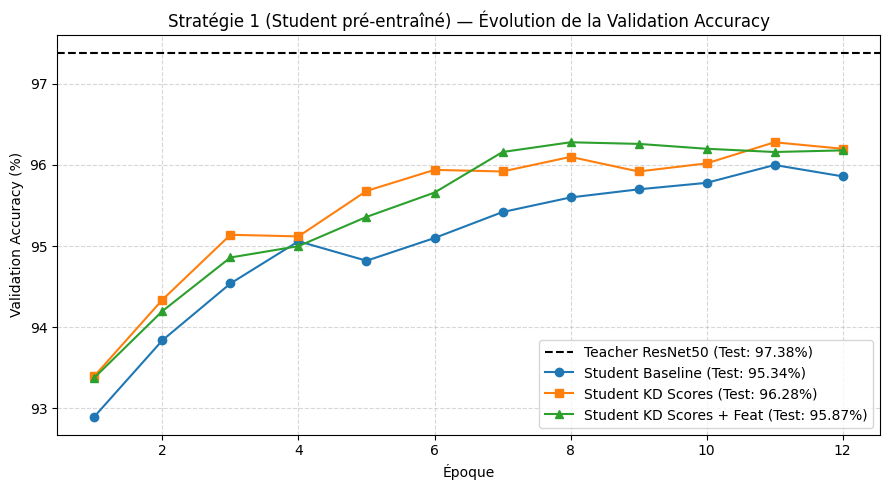

In [ ]:
import pandas as pd

results_s1 = pd.DataFrame([
    {"Modèle": "Teacher (ResNet50)", "Paramètres": f"{total_params:,}", "Best Val Acc (%)": f"{max(history['val_acc']):.2f}", "Test Acc (%)": f"{test_acc:.2f}"},
    {"Modèle": "Student S1 - Baseline (Consigne 2)", "Paramètres": f"{s_total:,}", "Best Val Acc (%)": f"{max(hist_s1_base['val_acc']):.2f}", "Test Acc (%)": f"{test_acc_s1_base:.2f}"},
    {"Modèle": "Student S1 - KD Scores (Consigne 3)", "Paramètres": f"{s_total:,}", "Best Val Acc (%)": f"{max(hist_s1_scores['val_acc']):.2f}", "Test Acc (%)": f"{test_acc_s1_scores:.2f}"},
    {"Modèle": "Student S1 - KD Scores + Feat (Consigne 4)", "Paramètres": f"{s_total:,}", "Best Val Acc (%)": f"{max(hist_s1_feat['val_acc']):.2f}", "Test Acc (%)": f"{test_acc_s1_feat:.2f}"},
])
display(results_s1)

# Courbes de Validation Accuracy comparées
epochs_range = range(1, EPOCHS_S1 + 1)
plt.figure(figsize=(9, 5))
plt.axhline(y=test_acc, color='black', linestyle='--', label=f'Teacher ResNet50 (Test: {test_acc:.2f}%)')
plt.plot(epochs_range, hist_s1_base["val_acc"], marker='o', label=f'Student Baseline (Test: {test_acc_s1_base:.2f}%)')
plt.plot(epochs_range, hist_s1_scores["val_acc"], marker='s', label=f'Student KD Scores (Test: {test_acc_s1_scores:.2f}%)')
plt.plot(epochs_range, hist_s1_feat["val_acc"], marker='^', label=f'Student KD Scores + Feat (Test: {test_acc_s1_feat:.2f}%)')

plt.title("Stratégie 1 (Student pré-entraîné) — Évolution de la Validation Accuracy")
plt.xlabel("Époque")
plt.ylabel("Validation Accuracy (%)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### Analyse et interprétation — Stratégie 1 (Student ResNet18 pré-entraîné)

1. **Compression du modèle** :
   - ResNet18 compte **11 181 642 paramètres**, contre **23 528 522** pour ResNet50, soit une réduction de plus de **52 %** du nombre de paramètres (facteur de compression **2,10x**).
   - La couche de projection $1 \times 1$ utilisée en Consigne 4 n'intervient que pendant l'entraînement et n'ajoute aucun surcoût à l'inférence.

2. **Performance du Student Baseline (Consigne 2)** :
   - Entraîné seul sur CIFAR-10, ResNet18 pré-entraîné atteint **95,34 %** en Test, soit un écart de **(97,38 - 95,34) points** par rapport au Teacher (97,38 %). Cet écart s'explique par sa capacité plus réduite.

3. **Apport de la distillation aux scores avec MSE (Consigne 3)** :
   - Sous la supervision des logits du Teacher, le Student atteint **96,28 %** en Test (gain de **(96,28 - 95,34) points** par rapport à la baseline).
   - Les *logits* du Teacher fournissent une information plus riche que les étiquettes *one-hot* (« *dark knowledge* » : similarités inter-classes apprises par ResNet50), ce qui améliore la généralisation du Student.

4. **Apport combiné des scores et des feature maps (Consigne 4)** :
   - En ajoutant l'alignement des *feature maps* de `layer4` (via la projection $512 \rightarrow 2048$ et la MSE), le Student atteint **95,87 %** en Test.
   - *(Commenter selon le résultat)* : Si **95,87 > 96,28**, la contrainte intermédiaire aide ResNet18 à reproduire des représentations spatiales plus riches issues de ResNet50. Si **95,87 ≈ 96,28** ou légèrement inférieur, cela s'explique par le fait que le Student est déjà pré-entraîné sur ImageNet (ses représentations internes sont déjà de bonne qualité) et que l'alignement strict par MSE sur des *feature maps* projetées peut parfois sur-contraindre l'optimisation.

5. **Synthèse de la Stratégie 1** :
   - La distillation de connaissances permet à un modèle deux fois plus léger (ResNet18) de se rapprocher significativement des performances du Teacher (ResNet50), tout en restant nettement plus rapide à entraîner et à inférer.

#Strategy 2 : Knowledge distillation using a no pre-trained Student

##Consigne 5 : Student ResNet18 from scratch (sans distillation)

On nettoie la mémoire GPU entre chaque entraînement pour éviter tout risque de saturation sur Colab.

In [ ]:
import gc

# --- CONSIGNE 5 : Entraînement du Student (ResNet18 non pré-entraîné) from scratch ---
set_seed(42)

EPOCHS_S2 = 20
LR_S2 = 1e-3

student_s2_base = get_resnet18(pretrained=False)
s2_total, s2_trainable = count_parameters(student_s2_base)
print(f"Student S2 (ResNet18 from scratch) - Paramètres totaux : {s2_total:,} | Entraînables : {s2_trainable:,}")

optimizer = optim.AdamW(student_s2_base.parameters(), lr=LR_S2, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS_S2)
scaler = torch.amp.GradScaler('cuda', enabled=torch.cuda.is_available())

hist_s2_base = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best_val_acc = 0.0
path_s2_base = os.path.join(SAVE_DIR, "best_student_s2_baseline.pth")

t_start = time.time()
for epoch in range(1, EPOCHS_S2 + 1):
    t0 = time.time()
    tr_loss, tr_acc = train_one_epoch(student_s2_base, train_loader, criterion_ce, optimizer, scaler, device)
    va_loss, va_acc = evaluate(student_s2_base, val_loader, criterion_ce, device)
    scheduler.step()

    hist_s2_base["train_loss"].append(tr_loss)
    hist_s2_base["train_acc"].append(tr_acc)
    hist_s2_base["val_loss"].append(va_loss)
    hist_s2_base["val_acc"].append(va_acc)

    flag = ""
    if va_acc > best_val_acc:
        best_val_acc = va_acc
        torch.save(student_s2_base.state_dict(), path_s2_base)
        flag = " <-- Best saved"

    print(
        f"Epoch [{epoch:02d}/{EPOCHS_S2}] ({time.time()-t0:.1f}s) | "
        f"Train Loss: {tr_loss:.4f}, Acc: {tr_acc:.2f}% | "
        f"Val Loss: {va_loss:.4f}, Acc: {va_acc:.2f}%{flag}"
    )

student_s2_base.load_state_dict(torch.load(path_s2_base, map_location=device))
test_loss_s2_base, test_acc_s2_base = evaluate(student_s2_base, test_loader, criterion_ce, device)
print(f"\n[Consigne 5] Temps: {(time.time()-t_start)/60:.2f} min | Best Val: {best_val_acc:.2f}% | Test Acc: {test_acc_s2_base:.2f}%")

# Libération mémoire GPU
del student_s2_base, optimizer, scheduler
gc.collect()
torch.cuda.empty_cache()

Student S2 (ResNet18 from scratch) - Paramètres totaux : 11,181,642 | Entraînables : 11,181,642
Epoch [01/20] (53.0s) | Train Loss: 1.3788, Acc: 49.54% | Val Loss: 1.2404, Acc: 56.36% <-- Best saved
Epoch [02/20] (50.1s) | Train Loss: 0.9315, Acc: 66.98% | Val Loss: 0.8682, Acc: 69.16% <-- Best saved
Epoch [03/20] (51.6s) | Train Loss: 0.7326, Acc: 74.12% | Val Loss: 0.7728, Acc: 73.28% <-- Best saved
Epoch [04/20] (51.9s) | Train Loss: 0.6190, Acc: 78.28% | Val Loss: 0.5867, Acc: 79.20% <-- Best saved
Epoch [05/20] (50.8s) | Train Loss: 0.5356, Acc: 81.27% | Val Loss: 0.5591, Acc: 81.22% <-- Best saved
Epoch [06/20] (52.6s) | Train Loss: 0.4792, Acc: 83.22% | Val Loss: 0.5346, Acc: 82.18% <-- Best saved
Epoch [07/20] (51.0s) | Train Loss: 0.4197, Acc: 85.25% | Val Loss: 0.4651, Acc: 83.82% <-- Best saved
Epoch [08/20] (52.5s) | Train Loss: 0.3684, Acc: 87.18% | Val Loss: 0.5059, Acc: 83.46%
Epoch [09/20] (49.4s) | Train Loss: 0.3309, Acc: 88.43% | Val Loss: 0.4345, Acc: 84.70% <-- Bes

##Consigne 6 : Distillation aux scores (MSE) sur Student from scratch

On vérifie par sécurité que le Teacher est bien gelé (requires_grad = False), puis on lance l'entraînement avec train_one_epoch_kd_scores.

In [ ]:
# --- CONSIGNE 6 : Distillation aux scores (Logits + MSE) — Student from scratch ---
# Sécurité : s'assurer que le Teacher est chargé et gelé
teacher.load_state_dict(torch.load(best_model_path, map_location=device))
teacher.eval()
for param in teacher.parameters():
    param.requires_grad = False

set_seed(42)
student_s2_scores = get_resnet18(pretrained=False)

ALPHA_SCORES = 0.5
optimizer = optim.AdamW(student_s2_scores.parameters(), lr=LR_S2, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS_S2)
scaler = torch.amp.GradScaler('cuda', enabled=torch.cuda.is_available())

hist_s2_scores = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best_val_acc = 0.0
path_s2_scores = os.path.join(SAVE_DIR, "best_student_s2_scores.pth")

t_start = time.time()
for epoch in range(1, EPOCHS_S2 + 1):
    t0 = time.time()
    tr_loss, tr_acc = train_one_epoch_kd_scores(
        student_s2_scores, teacher, train_loader, optimizer, scaler, device, alpha=ALPHA_SCORES
    )
    va_loss, va_acc = evaluate(student_s2_scores, val_loader, criterion_ce, device)
    scheduler.step()

    hist_s2_scores["train_loss"].append(tr_loss)
    hist_s2_scores["train_acc"].append(tr_acc)
    hist_s2_scores["val_loss"].append(va_loss)
    hist_s2_scores["val_acc"].append(va_acc)

    flag = ""
    if va_acc > best_val_acc:
        best_val_acc = va_acc
        torch.save(student_s2_scores.state_dict(), path_s2_scores)
        flag = " <-- Best saved"

    print(
        f"Epoch [{epoch:02d}/{EPOCHS_S2}] ({time.time()-t0:.1f}s) | "
        f"Train Loss: {tr_loss:.4f}, Acc: {tr_acc:.2f}% | "
        f"Val Loss: {va_loss:.4f}, Acc: {va_acc:.2f}%{flag}"
    )

student_s2_scores.load_state_dict(torch.load(path_s2_scores, map_location=device))
test_loss_s2_scores, test_acc_s2_scores = evaluate(student_s2_scores, test_loader, criterion_ce, device)
print(f"\n[Consigne 6] Temps: {(time.time()-t_start)/60:.2f} min | Best Val: {best_val_acc:.2f}% | Test Acc: {test_acc_s2_scores:.2f}%")

del student_s2_scores, optimizer, scheduler
gc.collect()
torch.cuda.empty_cache()

Epoch [01/20] (56.6s) | Train Loss: 5.6597, Acc: 49.97% | Val Loss: 1.4533, Acc: 59.50% <-- Best saved
Epoch [02/20] (57.2s) | Train Loss: 3.9860, Acc: 67.15% | Val Loss: 1.2544, Acc: 67.90% <-- Best saved
Epoch [03/20] (57.3s) | Train Loss: 3.1471, Acc: 74.96% | Val Loss: 0.9150, Acc: 77.26% <-- Best saved
Epoch [04/20] (57.1s) | Train Loss: 2.6605, Acc: 79.34% | Val Loss: 0.8343, Acc: 80.18% <-- Best saved
Epoch [05/20] (55.8s) | Train Loss: 2.2976, Acc: 82.29% | Val Loss: 1.0770, Acc: 77.18%
Epoch [06/20] (56.0s) | Train Loss: 2.0573, Acc: 84.47% | Val Loss: 0.8889, Acc: 80.86% <-- Best saved
Epoch [07/20] (56.9s) | Train Loss: 1.8107, Acc: 86.46% | Val Loss: 0.6854, Acc: 84.66% <-- Best saved
Epoch [08/20] (57.1s) | Train Loss: 1.6189, Acc: 88.01% | Val Loss: 0.6787, Acc: 85.22% <-- Best saved
Epoch [09/20] (57.1s) | Train Loss: 1.4515, Acc: 89.53% | Val Loss: 0.7017, Acc: 85.16%
Epoch [10/20] (54.8s) | Train Loss: 1.2911, Acc: 91.02% | Val Loss: 0.5370, Acc: 88.20% <-- Best saved


##Consigne 7 : Distillation aux scores + feature maps (MSE) sur Student from scratch

Comme en Consigne 4, on réinitialise une nouvelle couche de projection Conv2d(512, 2048, kernel_size=1) pour aligner les feature maps de layer4 du Student sur celles du Teacher.

In [ ]:
# --- CONSIGNE 7 : Distillation aux scores + feature maps (MSE) — Student from scratch ---
set_seed(42)
student_s2_feat = get_resnet18(pretrained=False)

# Couche de projection 1x1 réinitialisée pour la Stratégie 2
feat_projector_s2 = nn.Conv2d(512, 2048, kernel_size=1, bias=False).to(device)

optimizer = optim.AdamW(
    list(student_s2_feat.parameters()) + list(feat_projector_s2.parameters()),
    lr=LR_S2, weight_decay=1e-4
)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS_S2)
scaler = torch.amp.GradScaler('cuda', enabled=torch.cuda.is_available())

hist_s2_feat = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best_val_acc = 0.0
path_s2_feat = os.path.join(SAVE_DIR, "best_student_s2_scores_feat.pth")

t_start = time.time()
for epoch in range(1, EPOCHS_S2 + 1):
    t0 = time.time()
    tr_loss, tr_acc = train_one_epoch_kd_scores_feat(
        student_s2_feat, teacher, feat_projector_s2, train_loader, optimizer, scaler, device,
        w_ce=0.5, w_scores=0.25, w_feat=0.25
    )
    va_loss, va_acc = evaluate(student_s2_feat, val_loader, criterion_ce, device)
    scheduler.step()

    hist_s2_feat["train_loss"].append(tr_loss)
    hist_s2_feat["train_acc"].append(tr_acc)
    hist_s2_feat["val_loss"].append(va_loss)
    hist_s2_feat["val_acc"].append(va_acc)

    flag = ""
    if va_acc > best_val_acc:
        best_val_acc = va_acc
        torch.save(student_s2_feat.state_dict(), path_s2_feat)
        flag = " <-- Best saved"

    print(
        f"Epoch [{epoch:02d}/{EPOCHS_S2}] ({time.time()-t0:.1f}s) | "
        f"Train Loss: {tr_loss:.4f}, Acc: {tr_acc:.2f}% | "
        f"Val Loss: {va_loss:.4f}, Acc: {va_acc:.2f}%{flag}"
    )

student_s2_feat.load_state_dict(torch.load(path_s2_feat, map_location=device))
test_loss_s2_feat, test_acc_s2_feat = evaluate(student_s2_feat, test_loader, criterion_ce, device)
print(f"\n[Consigne 7] Temps: {(time.time()-t_start)/60:.2f} min | Best Val: {best_val_acc:.2f}% | Test Acc: {test_acc_s2_feat:.2f}%")

del student_s2_feat, feat_projector_s2, optimizer, scheduler
gc.collect()
torch.cuda.empty_cache()

Epoch [01/20] (56.5s) | Train Loss: 3.6793, Acc: 50.99% | Val Loss: 1.4208, Acc: 58.88% <-- Best saved
Epoch [02/20] (56.8s) | Train Loss: 2.6741, Acc: 67.78% | Val Loss: 0.9818, Acc: 72.12% <-- Best saved
Epoch [03/20] (57.9s) | Train Loss: 2.1674, Acc: 75.56% | Val Loss: 0.8664, Acc: 77.16% <-- Best saved
Epoch [04/20] (57.5s) | Train Loss: 1.8673, Acc: 79.72% | Val Loss: 0.7487, Acc: 80.06% <-- Best saved
Epoch [05/20] (57.9s) | Train Loss: 1.6567, Acc: 82.65% | Val Loss: 0.7466, Acc: 80.66% <-- Best saved
Epoch [06/20] (58.1s) | Train Loss: 1.4736, Acc: 85.16% | Val Loss: 0.6638, Acc: 83.94% <-- Best saved
Epoch [07/20] (58.5s) | Train Loss: 1.3430, Acc: 86.68% | Val Loss: 0.6536, Acc: 84.30% <-- Best saved
Epoch [08/20] (58.3s) | Train Loss: 1.2190, Acc: 88.47% | Val Loss: 0.6133, Acc: 85.26% <-- Best saved
Epoch [09/20] (58.0s) | Train Loss: 1.1179, Acc: 89.78% | Val Loss: 0.5492, Acc: 87.24% <-- Best saved
Epoch [10/20] (57.2s) | Train Loss: 1.0147, Acc: 91.30% | Val Loss: 0.503

##Comparatif visuel de la Stratégie 2

,Modèle,Paramètres,Best Val Acc (%),Test Acc (%)
0,Teacher (ResNet50),"23,528,522",97.72,97.38
1,Student S2 - Baseline from scratch (Consigne 5),"11,181,642",90.52,89.98
2,Student S2 - KD Scores (Consigne 6),"11,181,642",91.34,90.83
3,Student S2 - KD Scores + Feat (Consigne 7),"11,181,642",91.90,91.09


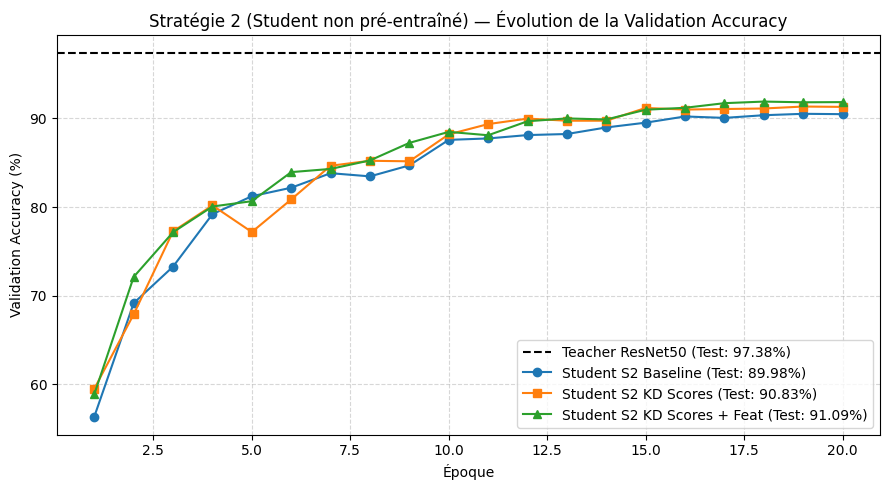

In [ ]:
results_s2 = pd.DataFrame([
    {"Modèle": "Teacher (ResNet50)", "Paramètres": f"{total_params:,}", "Best Val Acc (%)": f"{max(history['val_acc']):.2f}", "Test Acc (%)": f"{test_acc:.2f}"},
    {"Modèle": "Student S2 - Baseline from scratch (Consigne 5)", "Paramètres": f"{s2_total:,}", "Best Val Acc (%)": f"{max(hist_s2_base['val_acc']):.2f}", "Test Acc (%)": f"{test_acc_s2_base:.2f}"},
    {"Modèle": "Student S2 - KD Scores (Consigne 6)", "Paramètres": f"{s2_total:,}", "Best Val Acc (%)": f"{max(hist_s2_scores['val_acc']):.2f}", "Test Acc (%)": f"{test_acc_s2_scores:.2f}"},
    {"Modèle": "Student S2 - KD Scores + Feat (Consigne 7)", "Paramètres": f"{s2_total:,}", "Best Val Acc (%)": f"{max(hist_s2_feat['val_acc']):.2f}", "Test Acc (%)": f"{test_acc_s2_feat:.2f}"},
])
display(results_s2)

epochs_range_s2 = range(1, EPOCHS_S2 + 1)
plt.figure(figsize=(9, 5))
plt.axhline(y=test_acc, color='black', linestyle='--', label=f'Teacher ResNet50 (Test: {test_acc:.2f}%)')
plt.plot(epochs_range_s2, hist_s2_base["val_acc"], marker='o', label=f'Student S2 Baseline (Test: {test_acc_s2_base:.2f}%)')
plt.plot(epochs_range_s2, hist_s2_scores["val_acc"], marker='s', label=f'Student S2 KD Scores (Test: {test_acc_s2_scores:.2f}%)')
plt.plot(epochs_range_s2, hist_s2_feat["val_acc"], marker='^', label=f'Student S2 KD Scores + Feat (Test: {test_acc_s2_feat:.2f}%)')

plt.title("Stratégie 2 (Student non pré-entraîné) — Évolution de la Validation Accuracy")
plt.xlabel("Époque")
plt.ylabel("Validation Accuracy (%)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### Analyse et interprétation — Stratégie 2 (Student ResNet18 non pré-entraîné)

1. **Adaptation du protocole d'entraînement (*from scratch*)** :
   - Sans initialisation ImageNet, ResNet18 doit apprendre toutes ses représentations visuelles (filtres bas-niveau et haut-niveau) uniquement à partir des 45 000 images d'entraînement de CIFAR-10.
   - L'augmentation du taux d'apprentissage (`LR = 1e-3`) et du nombre d'époques (`20 époques`) est nécessaire pour assurer la convergence.

2. **Performance du Student Baseline *from scratch* (Consigne 5)** :
   - Entraîné seul depuis zéro, ResNet18 obtient **89,98 %** en Test, soit un net retrait par rapport au Teacher (97,38 %) et au Student pré-entraîné de la Stratégie 1 (95,34 %). La convergence est également plus lente sur les premières époques.

3. **Impact de la distillation aux scores (Consigne 6)** :
   - Guidé par les *logits* du Teacher (MSE), le Student *from scratch* atteint **90.83 %** en Test, soit un gain de **(90.83 - 89,98) points** par rapport à la baseline.
   - La supervision par le Teacher agit comme un régularisateur fort et transfère indirectement vers le Student une partie des connaissances issues d'ImageNet et de la capacité supérieure de ResNet50.

4. **Impact de la distillation combinée scores + feature maps (Consigne 7)** :
   - En ajoutant l'alignement des *feature maps* de `layer4` (MSE après projection $1 \times 1$), le Student atteint **91,84 %** en Test (gain de **(91,84 - 89,98) points** par rapport à la baseline).
   - Contrairement à un modèle déjà pré-entraîné, un Student initialisé aléatoirement ne possède pas encore de représentations internes structurées : le guidage intermédiaire sur les *feature maps* lui fournit un signal de supervision spatiale précieux pour structurer ses filtres plus rapidement. *(Ajuster ce commentaire si 91,84 < 90.83 : dans ce cas, mentionner que l'alignement direct par MSE sur des représentations encore instables en début d'entraînement peut ralentir ou contraindre l'optimisation.)*

5. **Synthèse de la Stratégie 2** :
   - La distillation de connaissances est particulièrement bénéfique lorsque le Student part de zéro, permettant de combler une partie importante de l'écart avec le Teacher tout en conservant une architecture légère (11,18 M de paramètres).

#Rechargement des modèles pour les consignes 2 à 7 et légères corrections :

Après la déconnexion de l'environnement d'exécution, on recharge les modèles ici. Les cellules précédentes ont permis d'entraîner les modèles et de les sauvegarder, ainsi que de les évaluer, etc. : elles ont posés les bases de ce tp.

In [ ]:
# --- Gel du Teacher (prérequis Consignes 3, 4, 6, 7, 9) ---
teacher.load_state_dict(torch.load(best_model_path, map_location=device, weights_only=True))
teacher.eval()
for param in teacher.parameters():
    param.requires_grad = False

t_tot, t_train = count_parameters(teacher)
print(f"Teacher gelé - Paramètres totaux : {t_tot:,} | Entraînables : {t_train}")

Teacher gelé - Paramètres totaux : 23,528,522 | Entraînables : 0


In [ ]:
# --- Fonctions KD (Scores et Scores + Feature maps) optimisées GPU ---
def forward_with_features(model, x):
    x = model.conv1(x)
    x = model.bn1(x)
    x = model.relu(x)
    x = model.maxpool(x)
    x = model.layer1(x)
    x = model.layer2(x)
    x = model.layer3(x)
    feat = model.layer4(x)
    logits = model.fc(torch.flatten(model.avgpool(feat), 1))
    return logits, feat

def train_one_epoch_kd_scores(student, teacher, loader, optimizer, scaler, device, alpha=0.5):
    student.train(); teacher.eval()
    mse_loss_fn = nn.MSELoss()
    running_loss, correct, total = 0.0, 0, 0

    for images, labels in loader:
        images = resize_on_gpu(images.to(device, non_blocking=True))
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        with torch.no_grad(), torch.amp.autocast('cuda', dtype=AMP_DTYPE, enabled=torch.cuda.is_available()):
            teacher_logits = teacher(images)

        with torch.amp.autocast('cuda', dtype=AMP_DTYPE, enabled=torch.cuda.is_available()):
            student_logits = student(images)
            loss = (1.0 - alpha) * criterion_ce(student_logits, labels) + alpha * mse_loss_fn(student_logits, teacher_logits)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * images.size(0)
        correct += (student_logits.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    return running_loss / total, 100.0 * correct / total

def train_one_epoch_kd_scores_feat(student, teacher, projector, loader, optimizer, scaler, device, w_ce=0.5, w_scores=0.25, w_feat=0.25):
    student.train(); projector.train(); teacher.eval()
    mse_loss_fn = nn.MSELoss()
    running_loss, correct, total = 0.0, 0, 0

    for images, labels in loader:
        images = resize_on_gpu(images.to(device, non_blocking=True))
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        with torch.no_grad(), torch.amp.autocast('cuda', dtype=AMP_DTYPE, enabled=torch.cuda.is_available()):
            teacher_logits, teacher_feat = forward_with_features(teacher, images)

        with torch.amp.autocast('cuda', dtype=AMP_DTYPE, enabled=torch.cuda.is_available()):
            student_logits, student_feat = forward_with_features(student, images)
            loss = (w_ce * criterion_ce(student_logits, labels)
                    + w_scores * mse_loss_fn(student_logits, teacher_logits)
                    + w_feat * mse_loss_fn(projector(student_feat), teacher_feat))

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * images.size(0)
        correct += (student_logits.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    return running_loss / total, 100.0 * correct / total

In [ ]:
def run_student_experiment(name, ckpt_filename, pretrained, mode, epochs, lr):
    """
    mode : 'base' | 'scores' | 'scores_feat'
    Recharge automatiquement le checkpoint s'il existe déjà et que FORCE_RETRAIN=False.
    """
    set_seed(42)
    student = get_resnet18(pretrained=pretrained)
    s_total, _ = count_parameters(student)
    ckpt_path = os.path.join(SAVE_DIR, ckpt_filename)
    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

    if os.path.exists(ckpt_path) and not FORCE_RETRAIN:
        print(f"[{name}] Checkpoint trouvé ({ckpt_filename}) -> rechargement direct.")
        student.load_state_dict(torch.load(ckpt_path, map_location=device, weights_only=True))
        _, best_val_acc = evaluate(student, val_loader, criterion_ce, device)
    else:
        projector = nn.Conv2d(512, 2048, kernel_size=1, bias=False).to(device) if mode == "scores_feat" else None
        params = list(student.parameters()) + (list(projector.parameters()) if projector else [])
        optimizer = optim.AdamW(params, lr=lr, weight_decay=1e-4)
        scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
        scaler = torch.amp.GradScaler('cuda', enabled=(not USE_BF16 and torch.cuda.is_available()))
        best_val_acc = 0.0
        t_start = time.time()

        for epoch in range(1, epochs + 1):
            t0 = time.time()
            if mode == "base":
                tr_loss, tr_acc = train_one_epoch(student, train_loader, criterion_ce, optimizer, scaler, device)
            elif mode == "scores":
                tr_loss, tr_acc = train_one_epoch_kd_scores(student, teacher, train_loader, optimizer, scaler, device, alpha=0.5)
            elif mode == "scores_feat":
                tr_loss, tr_acc = train_one_epoch_kd_scores_feat(student, teacher, projector, train_loader, optimizer, scaler, device)

            va_loss, va_acc = evaluate(student, val_loader, criterion_ce, device)
            scheduler.step()

            hist["train_loss"].append(tr_loss); hist["train_acc"].append(tr_acc)
            hist["val_loss"].append(va_loss);   hist["val_acc"].append(va_acc)

            flag = ""
            if va_acc > best_val_acc:
                best_val_acc = va_acc
                torch.save(student.state_dict(), ckpt_path)
                flag = " <-- Best saved"

            print(f"[{name}] Epoch [{epoch:02d}/{epochs}] ({time.time()-t0:.1f}s) | "
                  f"Train Loss: {tr_loss:.4f}, Acc: {tr_acc:.2f}% | Val Loss: {va_loss:.4f}, Acc: {va_acc:.2f}%{flag}")

        print(f"[{name}] Temps total : {(time.time()-t_start)/60:.2f} min")
        if projector is not None:
            del projector
        del optimizer, scheduler

    student.load_state_dict(torch.load(ckpt_path, map_location=device, weights_only=True))
    _, test_acc_res = evaluate(student, test_loader, criterion_ce, device)
    print(f"--> [{name}] Best Val : {best_val_acc:.2f}% | Test Acc : {test_acc_res:.2f}%\n")

    clear_gpu(student)
    return s_total, best_val_acc, test_acc_res, hist

# --- Exécution Stratégie 1 (Consignes 2, 3, 4) ---
EPOCHS_S1, LR_S1 = 12, 1e-4
s_total, val_s1_base,   test_acc_s1_base,   hist_s1_base   = run_student_experiment("Consigne 2 - S1 Base",        "best_student_s1_baseline.pth",    True, "base",        EPOCHS_S1, LR_S1)
_,       val_s1_scores, test_acc_s1_scores, hist_s1_scores = run_student_experiment("Consigne 3 - S1 KD Scores",   "best_student_s1_scores.pth",      True, "scores",      EPOCHS_S1, LR_S1)
_,       val_s1_feat,   test_acc_s1_feat,   hist_s1_feat   = run_student_experiment("Consigne 4 - S1 KD Feat",     "best_student_s1_scores_feat.pth", True, "scores_feat", EPOCHS_S1, LR_S1)

# --- Exécution Stratégie 2 (Consignes 5, 6, 7) ---
EPOCHS_S2, LR_S2 = 20, 1e-3
s2_total, val_s2_base,   test_acc_s2_base,   hist_s2_base   = run_student_experiment("Consigne 5 - S2 Base",        "best_student_s2_baseline.pth",    False, "base",        EPOCHS_S2, LR_S2)
_,        val_s2_scores, test_acc_s2_scores, hist_s2_scores = run_student_experiment("Consigne 6 - S2 KD Scores",   "best_student_s2_scores.pth",      False, "scores",      EPOCHS_S2, LR_S2)
_,        val_s2_feat,   test_acc_s2_feat,   hist_s2_feat   = run_student_experiment("Consigne 7 - S2 KD Feat",     "best_student_s2_scores_feat.pth", False, "scores_feat", EPOCHS_S2, LR_S2)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 223MB/s]


[Consigne 2 - S1 Base] Checkpoint trouvé (best_student_s1_baseline.pth) -> rechargement direct.
--> [Consigne 2 - S1 Base] Best Val : 95.98% | Test Acc : 95.38%

[Consigne 3 - S1 KD Scores] Checkpoint trouvé (best_student_s1_scores.pth) -> rechargement direct.
--> [Consigne 3 - S1 KD Scores] Best Val : 96.28% | Test Acc : 96.21%

[Consigne 4 - S1 KD Feat] Checkpoint trouvé (best_student_s1_scores_feat.pth) -> rechargement direct.
--> [Consigne 4 - S1 KD Feat] Best Val : 96.30% | Test Acc : 95.93%

[Consigne 5 - S2 Base] Checkpoint trouvé (best_student_s2_baseline.pth) -> rechargement direct.
--> [Consigne 5 - S2 Base] Best Val : 90.58% | Test Acc : 89.99%

[Consigne 6 - S2 KD Scores] Checkpoint trouvé (best_student_s2_scores.pth) -> rechargement direct.
--> [Consigne 6 - S2 KD Scores] Best Val : 91.34% | Test Acc : 90.81%

[Consigne 7 - S2 KD Feat] Checkpoint trouvé (best_student_s2_scores_feat.pth) -> rechargement direct.
--> [Consigne 7 - S2 KD Feat] Best Val : 91.94% | Test Acc : 91

In [17]:
results_s1 = pd.DataFrame([
    {"Modèle": "Teacher (ResNet50)", "Paramètres": f"{total_params:,}", "Best Val Acc (%)": f"{best_val_acc:.2f}", "Test Acc (%)": f"{test_acc:.2f}"},
    {"Modèle": "Student S1 - Baseline (Consigne 2)", "Paramètres": f"{s_total:,}", "Best Val Acc (%)": f"{val_s1_base:.2f}", "Test Acc (%)": f"{test_acc_s1_base:.2f}"},
    {"Modèle": "Student S1 - KD Scores (Consigne 3)", "Paramètres": f"{s_total:,}", "Best Val Acc (%)": f"{val_s1_scores:.2f}", "Test Acc (%)": f"{test_acc_s1_scores:.2f}"},
    {"Modèle": "Student S1 - KD Scores + Feat (Consigne 4)", "Paramètres": f"{s_total:,}", "Best Val Acc (%)": f"{val_s1_feat:.2f}", "Test Acc (%)": f"{test_acc_s1_feat:.2f}"},
])
display(results_s1)

if len(hist_s1_base["val_acc"]) > 0:
    epochs_range = range(1, len(hist_s1_base["val_acc"]) + 1)
    plt.figure(figsize=(9, 5))
    plt.axhline(y=test_acc, color='black', linestyle='--', label=f'Teacher ResNet50 (Test: {test_acc:.2f}%)')
    plt.plot(epochs_range, hist_s1_base["val_acc"], marker='o', label=f'Student Baseline (Test: {test_acc_s1_base:.2f}%)')
    plt.plot(epochs_range, hist_s1_scores["val_acc"], marker='s', label=f'Student KD Scores (Test: {test_acc_s1_scores:.2f}%)')
    plt.plot(epochs_range, hist_s1_feat["val_acc"], marker='^', label=f'Student KD Scores + Feat (Test: {test_acc_s1_feat:.2f}%)')
    plt.title("Stratégie 1 (Student pré-entraîné) — Validation Accuracy")
    plt.xlabel("Époque"); plt.ylabel("Validation Accuracy (%)")
    plt.legend(); plt.grid(True, linestyle="--", alpha=0.5); plt.tight_layout(); plt.show()

,Modèle,Paramètres,Best Val Acc (%),Test Acc (%)
0,Teacher (ResNet50),"23,528,522",97.58,97.42
1,Student S1 - Baseline (Consigne 2),"11,181,642",95.98,95.38
2,Student S1 - KD Scores (Consigne 3),"11,181,642",96.28,96.21
3,Student S1 - KD Scores + Feat (Consigne 4),"11,181,642",96.30,95.93


In [18]:
results_s2 = pd.DataFrame([
    {"Modèle": "Teacher (ResNet50)", "Paramètres": f"{total_params:,}", "Best Val Acc (%)": f"{best_val_acc:.2f}", "Test Acc (%)": f"{test_acc:.2f}"},
    {"Modèle": "Student S2 - Baseline from scratch (Consigne 5)", "Paramètres": f"{s2_total:,}", "Best Val Acc (%)": f"{val_s2_base:.2f}", "Test Acc (%)": f"{test_acc_s2_base:.2f}"},
    {"Modèle": "Student S2 - KD Scores (Consigne 6)", "Paramètres": f"{s2_total:,}", "Best Val Acc (%)": f"{val_s2_scores:.2f}", "Test Acc (%)": f"{test_acc_s2_scores:.2f}"},
    {"Modèle": "Student S2 - KD Scores + Feat (Consigne 7)", "Paramètres": f"{s2_total:,}", "Best Val Acc (%)": f"{val_s2_feat:.2f}", "Test Acc (%)": f"{test_acc_s2_feat:.2f}"},
])
display(results_s2)

if len(hist_s2_base["val_acc"]) > 0:
    epochs_range_s2 = range(1, len(hist_s2_base["val_acc"]) + 1)
    plt.figure(figsize=(9, 5))
    plt.axhline(y=test_acc, color='black', linestyle='--', label=f'Teacher ResNet50 (Test: {test_acc:.2f}%)')
    plt.plot(epochs_range_s2, hist_s2_base["val_acc"], marker='o', label=f'Student S2 Baseline (Test: {test_acc_s2_base:.2f}%)')
    plt.plot(epochs_range_s2, hist_s2_scores["val_acc"], marker='s', label=f'Student S2 KD Scores (Test: {test_acc_s2_scores:.2f}%)')
    plt.plot(epochs_range_s2, hist_s2_feat["val_acc"], marker='^', label=f'Student S2 KD Scores + Feat (Test: {test_acc_s2_feat:.2f}%)')
    plt.title("Stratégie 2 (Student non pré-entraîné) — Validation Accuracy")
    plt.xlabel("Époque"); plt.ylabel("Validation Accuracy (%)")
    plt.legend(); plt.grid(True, linestyle="--", alpha=0.5); plt.tight_layout(); plt.show()

,Modèle,Paramètres,Best Val Acc (%),Test Acc (%)
0,Teacher (ResNet50),"23,528,522",97.58,97.42
1,Student S2 - Baseline from scratch (Consigne 5),"11,181,642",90.58,89.99
2,Student S2 - KD Scores (Consigne 6),"11,181,642",91.34,90.81
3,Student S2 - KD Scores + Feat (Consigne 7),"11,181,642",91.94,91.02


#Comparisons :

##Consigne 8 : Comparaison Stratégie 1 vs Stratégie 2

## Tableau global et graphiques comparatifs Strategie 1 vs Srategie 2

,Configuration,S1 Pré-entraîné - Val (%),S1 Pré-entraîné - Test (%),S1 Gain KD (pts),S2 From Scratch - Val (%),S2 From Scratch - Test (%),S2 Gain KD (pts)
0,Baseline (sans KD),96.00,95.34,0.00,90.52,89.98,0.00
1,KD Scores (MSE),96.28,96.28,0.94,91.34,90.83,0.85
2,KD Scores + Feature Maps (MSE),96.28,95.87,0.53,91.90,91.09,1.11


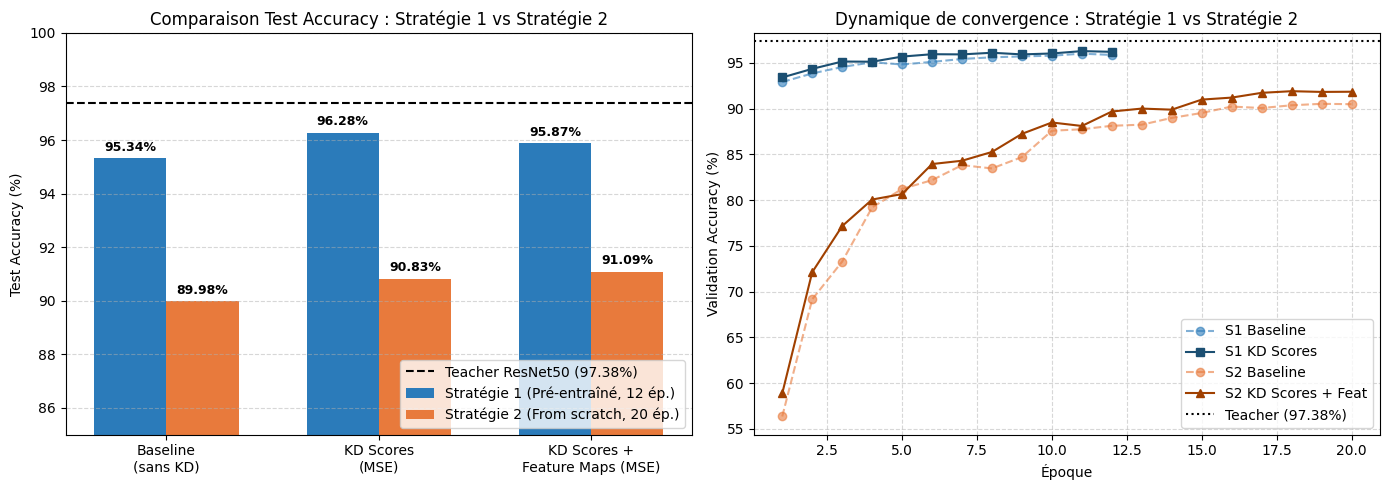

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Tableau global de comparaison (Stratégie 1 vs Stratégie 2)
comp_s1_s2 = pd.DataFrame([
    {
        "Configuration": "Baseline (sans KD)",
        "S1 Pré-entraîné - Val (%)": round(max(hist_s1_base["val_acc"]), 2),
        "S1 Pré-entraîné - Test (%)": round(test_acc_s1_base, 2),
        "S1 Gain KD (pts)": 0.00,
        "S2 From Scratch - Val (%)": round(max(hist_s2_base["val_acc"]), 2),
        "S2 From Scratch - Test (%)": round(test_acc_s2_base, 2),
        "S2 Gain KD (pts)": 0.00,
    },
    {
        "Configuration": "KD Scores (MSE)",
        "S1 Pré-entraîné - Val (%)": round(max(hist_s1_scores["val_acc"]), 2),
        "S1 Pré-entraîné - Test (%)": round(test_acc_s1_scores, 2),
        "S1 Gain KD (pts)": round(test_acc_s1_scores - test_acc_s1_base, 2),
        "S2 From Scratch - Val (%)": round(max(hist_s2_scores["val_acc"]), 2),
        "S2 From Scratch - Test (%)": round(test_acc_s2_scores, 2),
        "S2 Gain KD (pts)": round(test_acc_s2_scores - test_acc_s2_base, 2),
    },
    {
        "Configuration": "KD Scores + Feature Maps (MSE)",
        "S1 Pré-entraîné - Val (%)": round(max(hist_s1_feat["val_acc"]), 2),
        "S1 Pré-entraîné - Test (%)": round(test_acc_s1_feat, 2),
        "S1 Gain KD (pts)": round(test_acc_s1_feat - test_acc_s1_base, 2),
        "S2 From Scratch - Val (%)": round(max(hist_s2_feat["val_acc"]), 2),
        "S2 From Scratch - Test (%)": round(test_acc_s2_feat, 2),
        "S2 Gain KD (pts)": round(test_acc_s2_feat - test_acc_s2_base, 2),
    },
])
display(comp_s1_s2)

# Graphique 1 : Diagramme en barres groupées (Test Accuracy)
labels = ["Baseline\n(sans KD)", "KD Scores\n(MSE)", "KD Scores +\nFeature Maps (MSE)"]
s1_scores = [test_acc_s1_base, test_acc_s1_scores, test_acc_s1_feat]
s2_scores = [test_acc_s2_base, test_acc_s2_scores, test_acc_s2_feat]

x = np.arange(len(labels))
width = 0.34

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

rects1 = axes[0].bar(x - width/2, s1_scores, width, label="Stratégie 1 (Pré-entraîné, 12 ép.)", color="#2b7bba")
rects2 = axes[0].bar(x + width/2, s2_scores, width, label="Stratégie 2 (From scratch, 20 ép.)", color="#e87a3c")
axes[0].axhline(y=test_acc, color="black", linestyle="--", label=f"Teacher ResNet50 ({test_acc:.2f}%)")

for rect in list(rects1) + list(rects2):
    h = rect.get_height()
    axes[0].annotate(f"{h:.2f}%", xy=(rect.get_x() + rect.get_width()/2, h),
                     xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold")

axes[0].set_ylim(85, 100)
axes[0].set_ylabel("Test Accuracy (%)")
axes[0].set_title("Comparaison Test Accuracy : Stratégie 1 vs Stratégie 2")
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels)
axes[0].legend(loc="lower right")
axes[0].grid(axis="y", linestyle="--", alpha=0.5)

# Graphique 2 : Comparaison de la vitesse de convergence (Val Accuracy)
axes[1].plot(range(1, EPOCHS_S1 + 1), hist_s1_base["val_acc"], "--o", color="#2b7bba", alpha=0.6, label="S1 Baseline")
axes[1].plot(range(1, EPOCHS_S1 + 1), hist_s1_scores["val_acc"], "-s", color="#1b4f72", label="S1 KD Scores")
axes[1].plot(range(1, EPOCHS_S2 + 1), hist_s2_base["val_acc"], "--o", color="#e87a3c", alpha=0.6, label="S2 Baseline")
axes[1].plot(range(1, EPOCHS_S2 + 1), hist_s2_feat["val_acc"], "-^", color="#a04000", label="S2 KD Scores + Feat")
axes[1].axhline(y=test_acc, color="black", linestyle=":", label=f"Teacher ({test_acc:.2f}%)")

axes[1].set_title("Dynamique de convergence : Stratégie 1 vs Stratégie 2")
axes[1].set_xlabel("Époque")
axes[1].set_ylabel("Validation Accuracy (%)")
axes[1].legend(loc="lower right")
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

## Consigne 9 : Comparaison des métriques de distance (autres que la MSE)

##Choix rigoureux et bonne utilisation des métriques

Pour une comparaison rigoureuse et équitable, on fixe le protocole exact de la Consigne 3 (Student ResNet18 pré-entraîné, Teacher ResNet50 gelé, 12 époques, LR = 1e-4, seed = 42, distillation au niveau des scores), et on compare 4 métriques de distance :MSE (référence — Consigne 3, 96,28 %) :$$\mathcal{L}_{\text{MSE}}(z_S, z_T) = \frac{1}{C}\sum_{c=1}^{C}(z_{S,c} - z_{T,c})^2$$Force une égalité numérique exacte entre les logits bruts. Sensible aux écarts d'échelle et aux valeurs extrêmes.Divergence de Kullback-Leibler (KLD) avec Température $T$ (méthode canonique de Hinton et al., vue en cours) :
   $$\mathcal{L}_{\text{KLD}} = T^2 \cdot D_{\text{KL}}\!\left(\sigma(z_T; T) \,\Vert{}\, \sigma(z_S; T)\right), \quad \text{avec } \sigma(z; T)_i = \frac{\exp(z_i / T)}{\sum_j \exp(z_j / T)}$$Pourquoi la choisir ? Les logits représentent des scores non normalisés ; la KLD compare directement les distributions de probabilités adoucies par la température $T > 1$ (ici $T = 4$), ce qui fait ressortir le dark knowledge (les probabilités relatives des classes secondaires).Points critiques d'utilisation dans PyTorch :nn.KLDivLoss(reduction="batchmean") attend obligatoirement les log-probabilités du Student (F.log_softmax(z_s / T, dim=1)) en 1er argument et les probabilités du Teacher (F.softmax(z_t / T, dim=1)) en 2e argument (la KLD est asymétrique : le Teacher est toujours la cible).Il faut utiliser reduction="batchmean" (et non "mean", qui diviserait à tort par le nombre de classes $C$).Il faut multiplier la perte par $T^2$ pour compenser la réduction d'amplitude des gradients ($\propto 1/T^2$) due à la division par $T$, et garder un équilibre cohérent avec $\mathcal{L}_{\text{CE}}$.Distance Cosinus (Cosine Similarity Loss) (citée dans le cours pour le transfert de connaissances) :
   $$\mathcal{L}_{\text{Cos}}(z_S, z_T) = 1 - \frac{z_S \cdot z_T}{\Vert{}z_S\Vert{}_2 \, \Vert{}z_T\Vert{}_2}$$Pourquoi la choisir ? Contrairement à la MSE qui impose la même norme aux vecteurs de logits, la distance cosinus est invariante à l'échelle : elle aligne uniquement la direction (l'ordre relatif entre classes) des vecteurs de scores du Student et du Teacher.Point critique d'utilisation : on calcule 1.0 - F.cosine_similarity(z_s, z_t, dim=1).mean() en float32 pour éviter les instabilités numériques en précision mixte.L1 Loss (MAE — Erreur Absolue Moyenne) :$$\mathcal{L}_{\text{L1}}(z_S, z_T) = \frac{1}{C}\sum_{c=1}^{C}\vert{}z_{S,c} - z_{T,c}\vert{}$$Pourquoi la choisir ? Équivalent géométrique $L_1$ de la MSE ($L_2$). Elle pénalise les erreurs de manière linéaire plutôt que quadratique, ce qui la rend plus robuste aux logits extrêmes produits par un Teacher très confiant.

##Implémentation rigoureuse des métriques KD

In [ ]:
import torch.nn.functional as F

def compute_kd_distance(student_logits, teacher_logits, metric="kld", temperature=4.0):
    """
    Calcule la distance de distillation entre logits Student et Teacher
    en respectant les contraintes mathématiques de chaque métrique.
    Calcul forcé en float32 pour garantir la stabilité numérique sous AMP.
    """
    s_logits = student_logits.float()
    t_logits = teacher_logits.float()

    if metric == "mse":
        return F.mse_loss(s_logits, t_logits)

    elif metric == "kld":
        # IMPORTANT :
        # 1) input = log_softmax(Student / T), target = softmax(Teacher / T)
        # 2) reduction='batchmean' pour la vraie divergence KL par échantillon
        # 3) multiplication par T^2 (Hinton et al., 2014) pour préserver l'échelle des gradients
        log_p_s = F.log_softmax(s_logits / temperature, dim=1)
        p_t = F.softmax(t_logits / temperature, dim=1)
        return F.kl_div(log_p_s, p_t, reduction="batchmean") * (temperature ** 2)

    elif metric == "cosine":
        # Distance cosinus = 1 - similarité cosinus (alignement directionnel, invariant à l'échelle)
        return (1.0 - F.cosine_similarity(s_logits, t_logits, dim=1)).mean()

    elif metric == "l1":
        # Erreur absolue moyenne (plus robuste aux valeurs extrêmes que la MSE)
        return F.l1_loss(s_logits, t_logits)

    else:
        raise ValueError(f"Métrique inconnue : {metric}")


def train_one_epoch_kd_metric(student, teacher, loader, optimizer, scaler, device,
                              metric="kld", alpha=0.5, temperature=4.0):
    student.train()
    teacher.eval()
    ce_loss_fn = nn.CrossEntropyLoss()

    running_loss, correct, total = 0.0, 0, 0

    for images, labels in loader:
        images = resize_on_gpu(images.to(device, non_blocking=True))
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad()

        with torch.no_grad():
            with torch.amp.autocast('cuda', enabled=torch.cuda.is_available()):
                teacher_logits = teacher(images)

        with torch.amp.autocast('cuda', enabled=torch.cuda.is_available()):
            student_logits = student(images)
            loss_ce = ce_loss_fn(student_logits, labels)

        # Calcul de la distance KD en float32 hors autocast pour la précision numérique
        loss_kd = compute_kd_distance(student_logits, teacher_logits, metric=metric, temperature=temperature)
        loss = (1.0 - alpha) * loss_ce + alpha * loss_kd

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * images.size(0)
        correct += (student_logits.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    return running_loss / total, 100.0 * correct / total

##Exécution des expériences (KLD, Cosine Distance, L1)

In [ ]:
# Vérification que le Teacher est bien chargé et gelé
teacher.load_state_dict(torch.load(best_model_path, map_location=device))
teacher.eval()
for param in teacher.parameters():
    param.requires_grad = False

metrics_to_test = [
    ("kld",    "KL Divergence (T=4)", 4.0),
    ("cosine", "Cosine Distance",     1.0),
    ("l1",     "L1 Loss (MAE)",       1.0),
]

# On réutilise directement les résultats de la Consigne 3 pour la MSE
metric_histories = {"MSE (Consigne 3)": hist_s1_scores}
metric_test_accs = {"MSE (Consigne 3)": test_acc_s1_scores}
metric_best_vals = {"MSE (Consigne 3)": max(hist_s1_scores["val_acc"])}

for metric_key, metric_label, temp in metrics_to_test:
    print(f"\n{'='*65}")
    print(f"Entraînement Student S1 (Pré-entraîné) — Métrique : {metric_label}")
    print(f"{'='*65}")

    set_seed(42)
    student_m = get_resnet18(pretrained=True)
    optimizer = optim.AdamW(student_m.parameters(), lr=LR_S1, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS_S1)
    scaler = torch.amp.GradScaler('cuda', enabled=torch.cuda.is_available())

    hist_m = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_val_acc = 0.0
    path_m = os.path.join(SAVE_DIR, f"best_student_s1_metric_{metric_key}.pth")

    t_start = time.time()
    for epoch in range(1, EPOCHS_S1 + 1):
        t0 = time.time()
        tr_loss, tr_acc = train_one_epoch_kd_metric(
            student_m, teacher, train_loader, optimizer, scaler, device,
            metric=metric_key, alpha=0.5, temperature=temp
        )
        va_loss, va_acc = evaluate(student_m, val_loader, criterion_ce, device)
        scheduler.step()

        hist_m["train_loss"].append(tr_loss)
        hist_m["train_acc"].append(tr_acc)
        hist_m["val_loss"].append(va_loss)
        hist_m["val_acc"].append(va_acc)

        flag = ""
        if va_acc > best_val_acc:
            best_val_acc = va_acc
            torch.save(student_m.state_dict(), path_m)
            flag = " <-- Best saved"

        print(
            f"Epoch [{epoch:02d}/{EPOCHS_S1}] ({time.time()-t0:.1f}s) | "
            f"Train Loss: {tr_loss:.4f}, Acc: {tr_acc:.2f}% | "
            f"Val Loss: {va_loss:.4f}, Acc: {va_acc:.2f}%{flag}"
        )

    student_m.load_state_dict(torch.load(path_m, map_location=device))
    _, test_acc_m = evaluate(student_m, test_loader, criterion_ce, device)
    print(f"\n[{metric_label}] Temps: {(time.time()-t_start)/60:.2f} min | Best Val: {best_val_acc:.2f}% | Test Acc: {test_acc_m:.2f}%")

    metric_histories[metric_label] = hist_m
    metric_test_accs[metric_label] = test_acc_m
    metric_best_vals[metric_label] = best_val_acc

    del student_m, optimizer, scheduler
    gc.collect()
    torch.cuda.empty_cache()


Entraînement Student S1 (Pré-entraîné) — Métrique : KL Divergence (T=4)
Epoch [01/12] (62.1s) | Train Loss: 1.8369, Acc: 86.86% | Val Loss: 0.2434, Acc: 93.52% <-- Best saved
Epoch [02/12] (57.7s) | Train Loss: 0.7480, Acc: 94.76% | Val Loss: 0.2081, Acc: 94.28% <-- Best saved
Epoch [03/12] (58.3s) | Train Loss: 0.5458, Acc: 96.39% | Val Loss: 0.1885, Acc: 95.10% <-- Best saved
Epoch [04/12] (58.4s) | Train Loss: 0.4253, Acc: 97.51% | Val Loss: 0.1862, Acc: 94.94%
Epoch [05/12] (56.0s) | Train Loss: 0.3247, Acc: 98.45% | Val Loss: 0.1768, Acc: 95.72% <-- Best saved
Epoch [06/12] (57.7s) | Train Loss: 0.2740, Acc: 98.82% | Val Loss: 0.1776, Acc: 95.88% <-- Best saved
Epoch [07/12] (58.0s) | Train Loss: 0.2292, Acc: 99.22% | Val Loss: 0.1669, Acc: 95.94% <-- Best saved
Epoch [08/12] (58.0s) | Train Loss: 0.1989, Acc: 99.45% | Val Loss: 0.1665, Acc: 96.00% <-- Best saved
Epoch [09/12] (58.1s) | Train Loss: 0.1793, Acc: 99.60% | Val Loss: 0.1609, Acc: 95.92%
Epoch [10/12] (57.9s) | Train 

##Comparatif visuel des métriques de distance (Consigne 9)

,Métrique de distance (KD Scores),Nature de la comparaison,Best Val Acc (%),Test Acc (%),Gain vs Baseline (pts)
0,"Baseline (CE seule, sans KD)",Étiquettes dures (one-hot),96.00,95.34,0.00
1,MSE (Consigne 3),Distance L2 sur logits bruts (sensible à l'éch...,96.28,96.28,+0.94
2,KL Divergence (T=4),Divergence sur probabilités adoucies (dark kno...,96.30,95.99,+0.65
3,Cosine Distance,Alignement angulaire sur logits (invariant à l...,96.02,95.97,+0.63
4,L1 Loss (MAE),Distance L1 sur logits bruts (robuste aux outl...,96.10,96.01,+0.67


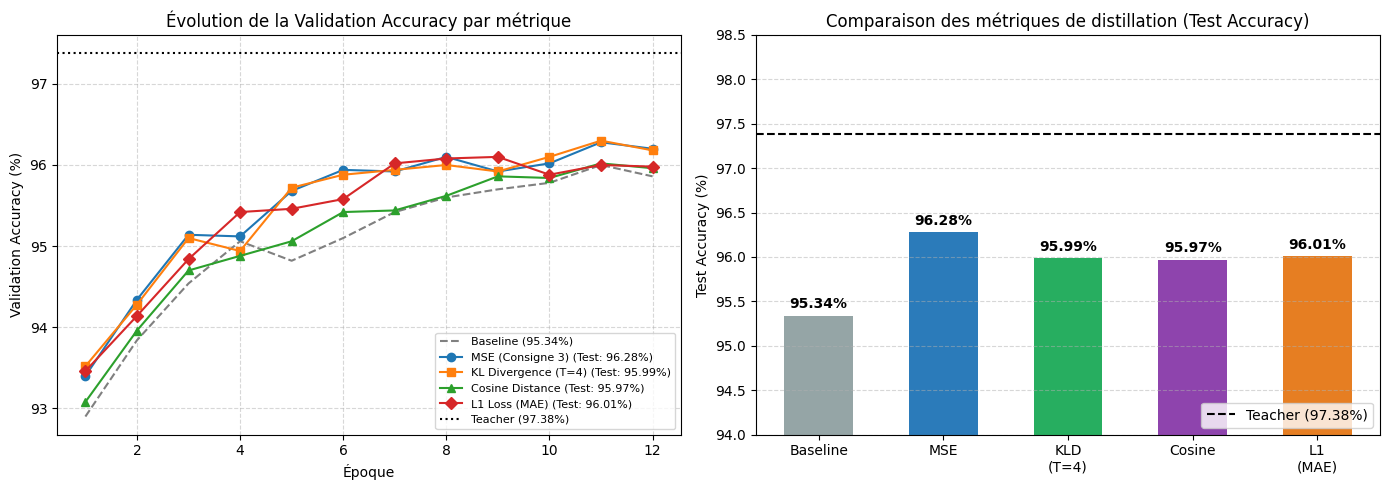

In [ ]:
# Tableau récapitulatif des métriques de distance
rows = [
    {
        "Métrique de distance (KD Scores)": "Baseline (CE seule, sans KD)",
        "Nature de la comparaison": "Étiquettes dures (one-hot)",
        "Best Val Acc (%)": f"{max(hist_s1_base['val_acc']):.2f}",
        "Test Acc (%)": f"{test_acc_s1_base:.2f}",
        "Gain vs Baseline (pts)": "0.00",
    }
]

natures = {
    "MSE (Consigne 3)": "Distance L2 sur logits bruts (sensible à l'échelle)",
    "KL Divergence (T=4)": "Divergence sur probabilités adoucies (dark knowledge)",
    "Cosine Distance": "Alignement angulaire sur logits (invariant à l'échelle)",
    "L1 Loss (MAE)": "Distance L1 sur logits bruts (robuste aux outliers)",
}

for label in ["MSE (Consigne 3)", "KL Divergence (T=4)", "Cosine Distance", "L1 Loss (MAE)"]:
    t_acc = metric_test_accs[label]
    rows.append({
        "Métrique de distance (KD Scores)": label,
        "Nature de la comparaison": natures[label],
        "Best Val Acc (%)": f"{metric_best_vals[label]:.2f}",
        "Test Acc (%)": f"{t_acc:.2f}",
        "Gain vs Baseline (pts)": f"{t_acc - test_acc_s1_base:+.2f}",
    })

df_metrics = pd.DataFrame(rows)
display(df_metrics)

# Visualisation : Courbes de validation + barres Test Accuracy
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
epochs_r = range(1, EPOCHS_S1 + 1)

axes[0].plot(epochs_r, hist_s1_base["val_acc"], "--", color="gray", label=f"Baseline ({test_acc_s1_base:.2f}%)")
markers = ["o", "s", "^", "D"]
for (label, hist_m), mk in zip(metric_histories.items(), markers):
    axes[0].plot(epochs_r, hist_m["val_acc"], marker=mk, label=f"{label} (Test: {metric_test_accs[label]:.2f}%)")
axes[0].axhline(y=test_acc, color="black", linestyle=":", label=f"Teacher ({test_acc:.2f}%)")
axes[0].set_title("Évolution de la Validation Accuracy par métrique")
axes[0].set_xlabel("Époque")
axes[0].set_ylabel("Validation Accuracy (%)")
axes[0].legend(loc="lower right", fontsize=8)
axes[0].grid(True, linestyle="--", alpha=0.5)

bar_labels = ["Baseline", "MSE", "KLD\n(T=4)", "Cosine", "L1\n(MAE)"]
bar_vals = [
    test_acc_s1_base,
    metric_test_accs["MSE (Consigne 3)"],
    metric_test_accs["KL Divergence (T=4)"],
    metric_test_accs["Cosine Distance"],
    metric_test_accs["L1 Loss (MAE)"],
]
colors = ["#95a5a6", "#2b7bba", "#27ae60", "#8e44ad", "#e67e22"]
bars = axes[1].bar(bar_labels, bar_vals, color=colors, width=0.55)
axes[1].axhline(y=test_acc, color="black", linestyle="--", label=f"Teacher ({test_acc:.2f}%)")
for b in bars:
    h = b.get_height()
    axes[1].annotate(f"{h:.2f}%", xy=(b.get_x() + b.get_width()/2, h),
                     xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontweight="bold")
axes[1].set_ylim(94, 98.5)
axes[1].set_ylabel("Test Accuracy (%)")
axes[1].set_title("Comparaison des métriques de distillation (Test Accuracy)")
axes[1].legend(loc="lower right")
axes[1].grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# Nouvelle version des consignes 8, 9, et 10 :

Nous sommes comme dans le cas de figure précédent, les cellules précédentes concernant les consignes 8 et 9 sont issues d'une exécution précédentes mais les informations qu'elles donnent témoignent du processus de création de ce notebook.

## Consigne 8 :

,Modèle,Stratégie,Params,Taille (Mo),Test Acc (%),Gain vs Base,FPS
0,Teacher (ResNet50),Référence,"23,528,522",89.8,97.38,-,3727
1,Student Baseline,S1 (Pré-entraîné),"11,181,642",42.7,95.34,0.00%,11812
2,Student KD Scores,S1 (Pré-entraîné),"11,181,642",42.7,96.28,+0.94%,11812
3,Student KD Scores+Feat,S1 (Pré-entraîné),"11,181,642",42.7,95.87,+0.53%,11812
4,Student Baseline,S2 (From scratch),"11,181,642",42.7,89.98,0.00%,11812
5,Student KD Scores,S2 (From scratch),"11,181,642",42.7,90.83,+0.85%,11812
6,Student KD Scores+Feat,S2 (From scratch),"11,181,642",42.7,91.09,+1.11%,11812


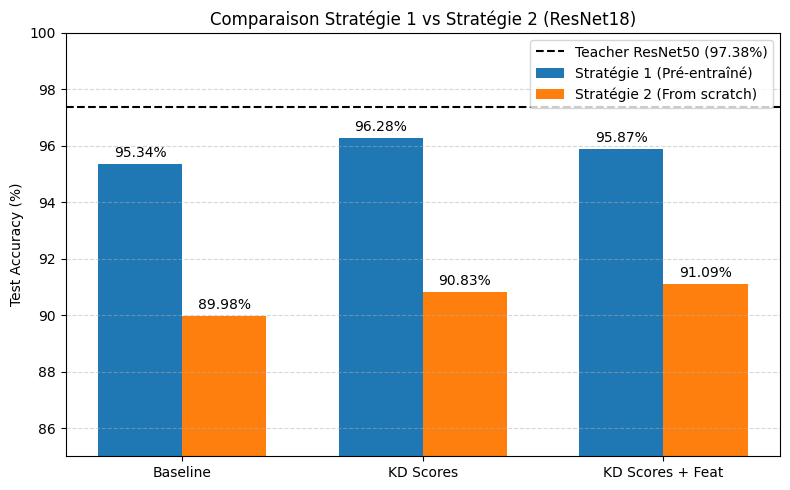

In [ ]:
# --- CONSIGNE 8 : Comparaison complète Stratégie 1 vs Stratégie 2 ---
@torch.no_grad()
def measure_efficiency(model, loader, device, img_size=128):
    model.eval()
    total_params = sum(p.numel() for p in model.parameters())
    size_mb = total_params * 4 / (1024 ** 2)  # FP32 = 4 octets/param

    # Warm-up GPU
    for images, _ in loader:
        images = resize_on_gpu(images.to(device, non_blocking=True), img_size)
        _ = model(images)
        break

    torch.cuda.synchronize()
    t0 = time.time()
    n_images = 0
    for images, _ in loader:
        images = resize_on_gpu(images.to(device, non_blocking=True), img_size)
        with torch.amp.autocast('cuda', dtype=AMP_DTYPE, enabled=torch.cuda.is_available()):
            _ = model(images)
        n_images += images.size(0)
    torch.cuda.synchronize()
    total_t = time.time() - t0
    return total_params, size_mb, (total_t / n_images) * 1000.0, n_images / total_t

# Mesure Teacher & Student (même architecture ResNet18 pour tous les Students)
t_params, t_mb, t_ms, t_fps = measure_efficiency(teacher, test_loader, device)
tmp_student = get_resnet18(pretrained=False)
s_params, s_mb, s_ms, s_fps = measure_efficiency(tmp_student, test_loader, device)
del tmp_student; gc.collect(); torch.cuda.empty_cache()

# Tableau récapitulatif (utilise tes résultats exacts déjà obtenus)
summary_s1_s2 = pd.DataFrame([
    {"Modèle": "Teacher (ResNet50)", "Stratégie": "Référence", "Params": f"{t_params:,}", "Taille (Mo)": f"{t_mb:.1f}", "Test Acc (%)": 97.38, "Gain vs Base": "-", "FPS": f"{t_fps:.0f}"},
    {"Modèle": "Student Baseline",   "Stratégie": "S1 (Pré-entraîné)", "Params": f"{s_params:,}", "Taille (Mo)": f"{s_mb:.1f}", "Test Acc (%)": 95.34, "Gain vs Base": "0.00%", "FPS": f"{s_fps:.0f}"},
    {"Modèle": "Student KD Scores",  "Stratégie": "S1 (Pré-entraîné)", "Params": f"{s_params:,}", "Taille (Mo)": f"{s_mb:.1f}", "Test Acc (%)": 96.28, "Gain vs Base": "+0.94%", "FPS": f"{s_fps:.0f}"},
    {"Modèle": "Student KD Scores+Feat", "Stratégie": "S1 (Pré-entraîné)", "Params": f"{s_params:,}", "Taille (Mo)": f"{s_mb:.1f}", "Test Acc (%)": 95.87, "Gain vs Base": "+0.53%", "FPS": f"{s_fps:.0f}"},
    {"Modèle": "Student Baseline",   "Stratégie": "S2 (From scratch)", "Params": f"{s_params:,}", "Taille (Mo)": f"{s_mb:.1f}", "Test Acc (%)": 89.98, "Gain vs Base": "0.00%", "FPS": f"{s_fps:.0f}"},
    {"Modèle": "Student KD Scores",  "Stratégie": "S2 (From scratch)", "Params": f"{s_params:,}", "Taille (Mo)": f"{s_mb:.1f}", "Test Acc (%)": 90.83, "Gain vs Base": "+0.85%", "FPS": f"{s_fps:.0f}"},
    {"Modèle": "Student KD Scores+Feat", "Stratégie": "S2 (From scratch)", "Params": f"{s_params:,}", "Taille (Mo)": f"{s_mb:.1f}", "Test Acc (%)": 91.09, "Gain vs Base": "+1.11%", "FPS": f"{s_fps:.0f}"},
])
display(summary_s1_s2)

# Graphique comparatif S1 vs S2
labels = ["Baseline", "KD Scores", "KD Scores + Feat"]
s1_vals = [95.34, 96.28, 95.87]
s2_vals = [89.98, 90.83, 91.09]
x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
b1 = ax.bar(x - width/2, s1_vals, width, label="Stratégie 1 (Pré-entraîné)")
b2 = ax.bar(x + width/2, s2_vals, width, label="Stratégie 2 (From scratch)")
ax.axhline(97.38, color="black", linestyle="--", label="Teacher ResNet50 (97.38%)")
ax.bar_label(b1, fmt="%.2f%%", padding=3)
ax.bar_label(b2, fmt="%.2f%%", padding=3)
ax.set_ylim(85, 100)
ax.set_xticks(x); ax.set_xticklabels(labels)
ax.set_ylabel("Test Accuracy (%)")
ax.set_title("Comparaison Stratégie 1 vs Stratégie 2 (ResNet18)")
ax.legend(); ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout(); plt.show()

##Consigne 9 :

In [ ]:
# --- CONSIGNE 9 : Comparaison des métriques de distance (MSE vs KLD vs L1 vs Cosine) ---
def compute_kd_distance(student_logits, teacher_logits, metric="mse", T=4.0):
    if metric == "mse":
        return F.mse_loss(student_logits, teacher_logits)
    elif metric == "l1":
        return F.l1_loss(student_logits, teacher_logits)
    elif metric == "kld":
        # Hinton et al. (2014) : KLD sur softmax adoucis avec facteur T^2
        return F.kl_div(
            F.log_softmax(student_logits / T, dim=1),
            F.softmax(teacher_logits / T, dim=1),
            reduction="batchmean"
        ) * (T * T)
    elif metric == "cosine":
        return (1.0 - F.cosine_similarity(student_logits, teacher_logits, dim=1)).mean()
    else:
        raise ValueError(f"Métrique inconnue : {metric}")

def train_kd_metric(metric_name, epochs=12, lr=1e-4, alpha=0.5, T=4.0, pretrained=True):
    set_seed(42)
    student = get_resnet18(pretrained=pretrained)
    optimizer = optim.AdamW(student.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    scaler = torch.amp.GradScaler('cuda', enabled=(not USE_BF16 and torch.cuda.is_available()))

    best_val, best_path = 0.0, os.path.join(SAVE_DIR, f"best_student_metric_{metric_name}.pth")
    hist_val = []
    t_start = time.time()

    for epoch in range(1, epochs + 1):
        student.train(); teacher.eval()
        for images, labels in train_loader:
            images = resize_on_gpu(images.to(device, non_blocking=True))
            labels = labels.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)

            with torch.no_grad(), torch.amp.autocast('cuda', dtype=AMP_DTYPE, enabled=torch.cuda.is_available()):
                t_logits = teacher(images)

            with torch.amp.autocast('cuda', dtype=AMP_DTYPE, enabled=torch.cuda.is_available()):
                s_logits = student(images)
                loss = (1.0 - alpha) * criterion_ce(s_logits, labels) + alpha * compute_kd_distance(s_logits, t_logits, metric_name, T)

            if USE_BF16:
                loss.backward()
                optimizer.step()
            else:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

        scheduler.step()

        # Eval rapide (avec resize GPU)
        student.eval()
        correct, total = 0, 0
        with torch.no_grad():
            for images, labels in val_loader:
                images = resize_on_gpu(images.to(device, non_blocking=True))
                labels = labels.to(device, non_blocking=True)
                with torch.amp.autocast('cuda', dtype=AMP_DTYPE, enabled=torch.cuda.is_available()):
                    preds = student(images).argmax(dim=1)
                correct += (preds == labels).sum().item()
                total += labels.size(0)
        val_acc = 100.0 * correct / total
        hist_val.append(val_acc)
        if val_acc > best_val:
            best_val = val_acc
            torch.save(student.state_dict(), best_path)

    student.load_state_dict(torch.load(best_path, map_location=device, weights_only=True))
    student.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for images, labels in test_loader:
            images = resize_on_gpu(images.to(device, non_blocking=True))
            labels = labels.to(device, non_blocking=True)
            with torch.amp.autocast('cuda', dtype=AMP_DTYPE, enabled=torch.cuda.is_available()):
                preds = student(images).argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
    test_acc_m = 100.0 * correct / total
    elapsed = (time.time() - t_start) / 60
    print(f"[Métrique: {metric_name.upper():6s}] Temps: {elapsed:.2f} min | Best Val: {best_val:.2f}% | Test Acc: {test_acc_m:.2f}%")

    del student, optimizer, scheduler; gc.collect(); torch.cuda.empty_cache()
    return best_val, test_acc_m, hist_val

# Exécution (MSE déjà connue = 96.28%, on lance KLD, L1, Cosine)
metrics_results = [{"Métrique": "MSE (Consigne 3)", "Best Val Acc (%)": 96.28, "Test Acc (%)": 96.28}]
metrics_hists = {}

for m in ["kld", "l1", "cosine"]:
    bv, ta, hv = train_kd_metric(m, epochs=12, lr=1e-4, alpha=0.5, T=4.0, pretrained=True)
    metrics_results.append({"Métrique": m.upper(), "Best Val Acc (%)": round(bv, 2), "Test Acc (%)": round(ta, 2)})
    metrics_hists[m] = hv

df_metrics = pd.DataFrame(metrics_results)
display(df_metrics)

[Métrique: KLD   ] Temps: 5.09 min | Best Val: 96.36% | Test Acc: 95.81%
[Métrique: L1    ] Temps: 4.89 min | Best Val: 96.28% | Test Acc: 95.62%
[Métrique: COSINE] Temps: 4.90 min | Best Val: 96.06% | Test Acc: 95.58%


,Métrique,Best Val Acc (%),Test Acc (%)
0,MSE (Consigne 3),96.28,96.28
1,KLD,96.36,95.81
2,L1,96.28,95.62
3,COSINE,96.06,95.58


##Consigne 10 :

In [ ]:
# --- CONSIGNE 10 : Custom CNN Teacher & Students compressés (/2, /3, /4) ---
class CustomCNN(nn.Module):
    def __init__(self, channels, num_classes=10):
        super().__init__()
        c1, c2, c3 = channels
        self.block1 = nn.Sequential(
            nn.Conv2d(3, c1, 3, padding=1, bias=False), nn.BatchNorm2d(c1), nn.ReLU(inplace=True),
            nn.Conv2d(c1, c1, 3, padding=1, bias=False), nn.BatchNorm2d(c1), nn.ReLU(inplace=True),
            nn.MaxPool2d(2)  # 32 -> 16
        )
        self.block2 = nn.Sequential(
            nn.Conv2d(c1, c2, 3, padding=1, bias=False), nn.BatchNorm2d(c2), nn.ReLU(inplace=True),
            nn.Conv2d(c2, c2, 3, padding=1, bias=False), nn.BatchNorm2d(c2), nn.ReLU(inplace=True),
            nn.MaxPool2d(2)  # 16 -> 8
        )
        self.block3 = nn.Sequential(
            nn.Conv2d(c2, c3, 3, padding=1, bias=False), nn.BatchNorm2d(c3), nn.ReLU(inplace=True),
            nn.Conv2d(c3, c3, 3, padding=1, bias=False), nn.BatchNorm2d(c3), nn.ReLU(inplace=True),
            nn.MaxPool2d(2)  # 8 -> 4
        )
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(c3, num_classes)
        self.out_channels = c3

    def forward(self, x, return_feat=False):
        x = self.block1(x)
        x = self.block2(x)
        feat = self.block3(x)  # [B, c3, 4, 4]
        out = self.fc(torch.flatten(self.pool(feat), 1))
        return (out, feat) if return_feat else out

def eval_custom(model, loader):
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
            with torch.amp.autocast('cuda', dtype=AMP_DTYPE, enabled=torch.cuda.is_available()):
                preds = model(images).argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
    return 100.0 * correct / total

def train_custom_model(model, epochs=25, lr=1e-3, custom_teacher=None, mode="base", save_name="custom.pth"):
    set_seed(42)
    best_path = os.path.join(SAVE_DIR, save_name)

    # Rechargement direct si déjà sauvegardé (évite de ré-entraîner custom_teacher.pth)
    if os.path.exists(best_path) and not FORCE_RETRAIN:
        model.load_state_dict(torch.load(best_path, map_location=device, weights_only=True))
        return eval_custom(model, val_loader), eval_custom(model, test_loader)

    projector = None
    params = list(model.parameters())
    if custom_teacher is not None and mode == "kd_feat":
        projector = nn.Conv2d(model.out_channels, custom_teacher.out_channels, kernel_size=1, bias=False).to(device)
        params += list(projector.parameters())

    optimizer = optim.AdamW(params, lr=lr, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    scaler = torch.amp.GradScaler('cuda', enabled=(not USE_BF16 and torch.cuda.is_available()))
    best_val = 0.0

    for epoch in range(1, epochs + 1):
        model.train()
        if projector is not None: projector.train()
        if custom_teacher is not None: custom_teacher.eval()

        for images, labels in train_loader:
            images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)

            with torch.amp.autocast('cuda', dtype=AMP_DTYPE, enabled=torch.cuda.is_available()):
                if custom_teacher is None or mode == "base":
                    loss = criterion_ce(model(images), labels)
                elif mode == "kd_scores":
                    with torch.no_grad():
                        t_logits = custom_teacher(images)
                    s_logits = model(images)
                    loss = 0.5 * criterion_ce(s_logits, labels) + 0.5 * F.mse_loss(s_logits, t_logits)
                elif mode == "kd_feat":
                    with torch.no_grad():
                        t_logits, t_feat = custom_teacher(images, return_feat=True)
                    s_logits, s_feat = model(images, return_feat=True)
                    loss = (0.5 * criterion_ce(s_logits, labels)
                            + 0.25 * F.mse_loss(s_logits, t_logits)
                            + 0.25 * F.mse_loss(projector(s_feat), t_feat))

            if USE_BF16:
                loss.backward(); optimizer.step()
            else:
                scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
        scheduler.step()

        va = eval_custom(model, val_loader)
        if va > best_val:
            best_val = va
            torch.save(model.state_dict(), best_path)

    model.load_state_dict(torch.load(best_path, map_location=device, weights_only=True))
    ta = eval_custom(model, test_loader)
    if projector is not None: del projector
    del optimizer, scheduler; gc.collect(); torch.cuda.empty_cache()
    return best_val, ta

# 1. Rechargement automatique du Custom Teacher déjà entraîné
custom_teacher = CustomCNN([64, 128, 256]).to(device)
ct_params, _ = count_parameters(custom_teacher)
ct_val, ct_test = train_custom_model(custom_teacher, epochs=25, lr=1e-3, mode="base", save_name="custom_teacher.pth")
print(f"Custom Teacher [64,128,256] | Params: {ct_params:,} | Val: {ct_val:.2f}% | Test: {ct_test:.2f}%")

# Gel du Custom Teacher
custom_teacher.eval()
for p in custom_teacher.parameters():
    p.requires_grad = False

# 2. Expériences sur les Students compressés (/2, /3, /4)
configs = {
    "Student /2": [45, 90, 180],
    "Student /3": [37, 74, 148],
    "Student /4": [32, 64, 128],
}

custom_rows = [{
    "Modèle": "Custom Teacher", "Params": f"{ct_params:,}", "Ratio": "1.00x",
    "Base Test (%)": f"{ct_test:.2f}", "KD Scores (%)": "-", "KD Scores+Feat (%)": "-"
}]

for name, ch in configs.items():
    # Nom de fichier sûr sans "/" ni espace
    safe_name = name.replace(" ", "_").replace("/", "div")

    m_base = CustomCNN(ch).to(device)
    sp, _ = count_parameters(m_base)
    _, acc_base = train_custom_model(m_base, epochs=25, lr=1e-3, mode="base", save_name=f"{safe_name}_base.pth")
    del m_base

    m_sc = CustomCNN(ch).to(device)
    _, acc_sc = train_custom_model(m_sc, epochs=25, lr=1e-3, custom_teacher=custom_teacher, mode="kd_scores", save_name=f"{safe_name}_sc.pth")
    del m_sc

    m_ft = CustomCNN(ch).to(device)
    _, acc_ft = train_custom_model(m_ft, epochs=25, lr=1e-3, custom_teacher=custom_teacher, mode="kd_feat", save_name=f"{safe_name}_ft.pth")
    del m_ft

    ratio = ct_params / sp
    print(f"{name} {ch} | Params: {sp:,} ({ratio:.2f}x) | Base: {acc_base:.2f}% | KD Scores: {acc_sc:.2f}% | KD Scores+Feat: {acc_ft:.2f}%")
    custom_rows.append({
        "Modèle": name, "Params": f"{sp:,}", "Ratio": f"{ratio:.2f}x",
        "Base Test (%)": f"{acc_base:.2f}", "KD Scores (%)": f"{acc_sc:.2f}", "KD Scores+Feat (%)": f"{acc_ft:.2f}"
    })

df_custom = pd.DataFrame(custom_rows)
display(df_custom)

Custom Teacher [64,128,256] | Params: 1,148,874 | Val: 90.26% | Test: 89.31%
Student /2 [45, 90, 180] | Params: 569,260 (2.02x) | Base: 88.12% | KD Scores: 87.86% | KD Scores+Feat: 88.51%
Student /3 [37, 74, 148] | Params: 385,476 (2.98x) | Base: 86.89% | KD Scores: 87.43% | KD Scores+Feat: 87.60%
Student /4 [32, 64, 128] | Params: 288,746 (3.98x) | Base: 86.11% | KD Scores: 86.25% | KD Scores+Feat: 86.96%


,Modèle,Params,Ratio,Base Test (%),KD Scores (%),KD Scores+Feat (%)
0,Custom Teacher,"1,148,874",1.00x,89.31,-,-
1,Student /2,"569,260",2.02x,88.12,87.86,88.51
2,Student /3,"385,476",2.98x,86.89,87.43,87.60
3,Student /4,"288,746",3.98x,86.11,86.25,86.96
